In [ ]:
import os
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
    RandomizedSearchCV, cross_validate, cross_val_predict
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay, brier_score_loss
)
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibrationDisplay

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC
from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

In [ ]:
df=pd.read_csv("hackathon_preli_dataset - bangladesh_dengue_large_dataset.csv")
df

,date,city,ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases
0,2016-01-04,Chattogram,CCC_Ward_01,64024,0.87,0.46,18.32,26.54,14.13,0.00,59.24,0
1,2016-01-11,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.24,26.95,16.71,2.02,61.63,0
2,2016-01-18,Chattogram,CCC_Ward_01,64024,0.87,0.46,20.94,25.05,14.84,0.00,60.50,0
3,2016-01-25,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.75,27.20,17.58,1.52,69.02,0
4,2016-02-01,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.39,28.02,16.98,0.94,60.50,0
...,...,...,...,...,...,...,...,...,...,...,...,...
31315,2025-12-01,Narayanganj,NCC_Ward_05,40043,0.90,0.34,17.73,23.49,13.06,9.53,53.21,0
31316,2025-12-08,Narayanganj,NCC_Ward_05,40043,0.90,0.34,20.54,24.74,15.85,0.13,67.46,0
31317,2025-12-15,Narayanganj,NCC_Ward_05,40043,0.90,0.34,21.98,27.62,15.08,8.24,65.93,0
31318,2025-12-22,Narayanganj,NCC_Ward_05,40043,0.90,0.34,22.23,26.90,18.41,4.11,57.05,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31320 entries, 0 to 31319
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   date                      31320 non-null  object 
 1   city                      31320 non-null  object 
 2   ward_id                   31320 non-null  object 
 3   population_density_sqkm   31320 non-null  int64  
 4   water_logging_risk_index  31320 non-null  float64
 5   sanitation_score          31320 non-null  float64
 6   avg_temp_c                31320 non-null  float64
 7   max_temp_c                31320 non-null  float64
 8   min_temp_c                31320 non-null  float64
 9   rainfall_mm               31320 non-null  float64
 10  relative_humidity_pct     31320 non-null  float64
 11  dengue_cases              31320 non-null  int64  
dtypes: float64(7), int64(2), object(3)
memory usage: 2.9+ MB


In [ ]:
df.describe()

,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases
count,31320.000000,31320.000000,31320.000000,31320.000000,31320.000000,31320.000000,31320.000000,31320.000000,31320.000000
mean,43157.733333,0.579333,0.554667,26.922804,31.889061,21.949425,35.630268,71.176132,2.636398
std,14865.377799,0.237903,0.191597,4.482042,4.516627,4.527965,50.237519,12.968610,4.607737
min,18314.000000,0.220000,0.250000,15.740000,23.120000,13.060000,0.000000,41.840000,0.000000
25%,30573.500000,0.377500,0.380000,22.880000,27.850000,18.000000,0.920000,60.467500,0.000000
50%,42854.000000,0.545000,0.570000,26.850000,31.505000,21.670000,8.370000,68.220000,0.000000
75%,54168.250000,0.820000,0.712500,31.022500,35.990000,25.970000,59.420000,83.980000,4.000000
max,74252.000000,0.940000,0.880000,37.510000,40.790000,31.640000,268.830000,99.000000,41.000000


In [ ]:
# Check lag feature missing values
lag_columns = [
    'rainfall_lag_1w',
    'rainfall_lag_2w',
    'rainfall_lag_3w',
    'rainfall_lag_4w',
    'temp_lag_1w',
    'temp_lag_2w',
    'temp_lag_3w',
    'temp_lag_4w',
    'humidity_lag_1w',
    'humidity_lag_2w',
    'humidity_lag_3w',
    'humidity_lag_4w'
]

print(df[lag_columns].isnull().sum())

rainfall_lag_1w     60
rainfall_lag_2w    120
rainfall_lag_3w    180
rainfall_lag_4w    240
temp_lag_1w         60
temp_lag_2w        120
temp_lag_3w        180
temp_lag_4w        240
humidity_lag_1w     60
humidity_lag_2w    120
humidity_lag_3w    180
humidity_lag_4w    240
dtype: int64


In [ ]:
df.groupby('ward_id')[lag_columns].apply(
    lambda x: x.isnull().sum()
).head()

,rainfall_lag_1w,rainfall_lag_2w,rainfall_lag_3w,rainfall_lag_4w,temp_lag_1w,temp_lag_2w,temp_lag_3w,temp_lag_4w,humidity_lag_1w,humidity_lag_2w,humidity_lag_3w,humidity_lag_4w
ward_id,,,,,,,,,,,,
CCC_Ward_01,1,2,3,4,1,2,3,4,1,2,3,4
CCC_Ward_02,1,2,3,4,1,2,3,4,1,2,3,4
CCC_Ward_03,1,2,3,4,1,2,3,4,1,2,3,4
CCC_Ward_04,1,2,3,4,1,2,3,4,1,2,3,4
CCC_Ward_05,1,2,3,4,1,2,3,4,1,2,3,4


In [ ]:
print("Current shape:", df.shape)

print("\nMissing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Current shape: (31320, 27)

Missing values: 1800

Duplicate rows: 0


In [ ]:
df['date'] = pd.to_datetime(df['date'])

print("Data type:", df['date'].dtype)
print("Start Date:", df['date'].min())
print("End Date:", df['date'].max())

Data type: datetime64[ns]
Start Date: 2016-01-04 00:00:00
End Date: 2025-12-29 00:00:00


In [ ]:
print("Unique Cities:", df['city'].nunique())
print("Unique Wards:", df['ward_id'].nunique())

print("\nCities:")
print(df['city'].unique())

Unique Cities: 5
Unique Wards: 60

Cities:
['Chattogram' 'Dhaka North' 'Dhaka South' 'Gazipur' 'Narayanganj']


In [ ]:
df['dengue_cases'].describe()

,dengue_cases
count,31320.000000
mean,2.636398
std,4.607737
min,0.000000
25%,0.000000
50%,0.000000
75%,4.000000
max,41.000000


In [ ]:
# Sort data by ward and date
df = df.sort_values(
    by=['ward_id', 'date']
).reset_index(drop=True)

# Check chronological ordering
is_sorted = df.groupby('ward_id')['date'].apply(
    lambda x: x.is_monotonic_increasing
)

print("All wards chronologically sorted:", is_sorted.all())

All wards chronologically sorted: True


In [ ]:
# Calculate date differences for each ward
df['date_diff'] = df.groupby('ward_id')['date'].diff()

print(df['date_diff'].value_counts(dropna=False))

date_diff
7 days    31260
NaT          60
Name: count, dtype: int64


In [ ]:
weekly_check = df.groupby('ward_id')['date'].apply(
    lambda x: (x.diff().dropna() == pd.Timedelta(days=7)).all()
)

print("All wards have continuous weekly dates:", weekly_check.all())

All wards have continuous weekly dates: True


In [ ]:
# Check temperature consistency
invalid_temp = df[
    (df['min_temp_c'] > df['avg_temp_c']) |
    (df['avg_temp_c'] > df['max_temp_c'])
]

print("Invalid temperature records:", len(invalid_temp))

Invalid temperature records: 0


In [ ]:
non_negative_columns = [
    'population_density_sqkm',
    'rainfall_mm',
    'dengue_cases',
    'water_logging_risk_index',
    'sanitation_score'
]

for col in non_negative_columns:
    print(
        f"{col}:",
        (df[col] < 0).sum(),
        "negative values"
    )

population_density_sqkm: 0 negative values
rainfall_mm: 0 negative values
dengue_cases: 0 negative values
water_logging_risk_index: 0 negative values
sanitation_score: 0 negative values


In [ ]:
environmental_columns = [
    'population_density_sqkm',
    'water_logging_risk_index',
    'sanitation_score'
]

df[environmental_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
population_density_sqkm,31320.0,43157.733333,14865.377799,18314.00,30573.5000,42854.000,54168.2500,74252.00
water_logging_risk_index,31320.0,0.579333,0.237903,0.22,0.3775,0.545,0.8200,0.94
sanitation_score,31320.0,0.554667,0.191597,0.25,0.3800,0.570,0.7125,0.88


In [ ]:
ward_features = [
    'population_density_sqkm',
    'water_logging_risk_index',
    'sanitation_score'
]

ward_consistency = df.groupby('ward_id')[
    ward_features
].nunique()

print(ward_consistency.head(15))

              population_density_sqkm  water_logging_risk_index  \
ward_id                                                           
CCC_Ward_01                         1                         1   
CCC_Ward_02                         1                         1   
CCC_Ward_03                         1                         1   
CCC_Ward_04                         1                         1   
CCC_Ward_05                         1                         1   
CCC_Ward_06                         1                         1   
CCC_Ward_07                         1                         1   
CCC_Ward_08                         1                         1   
CCC_Ward_09                         1                         1   
CCC_Ward_10                         1                         1   
DNCC_Ward_01                        1                         1   
DNCC_Ward_02                        1                         1   
DNCC_Ward_03                        1                         

In [ ]:
duplicate_ward_dates = df.duplicated(
    subset=['ward_id', 'date']
).sum()

print("Duplicate ward-date records:", duplicate_ward_dates)

Duplicate ward-date records: 0


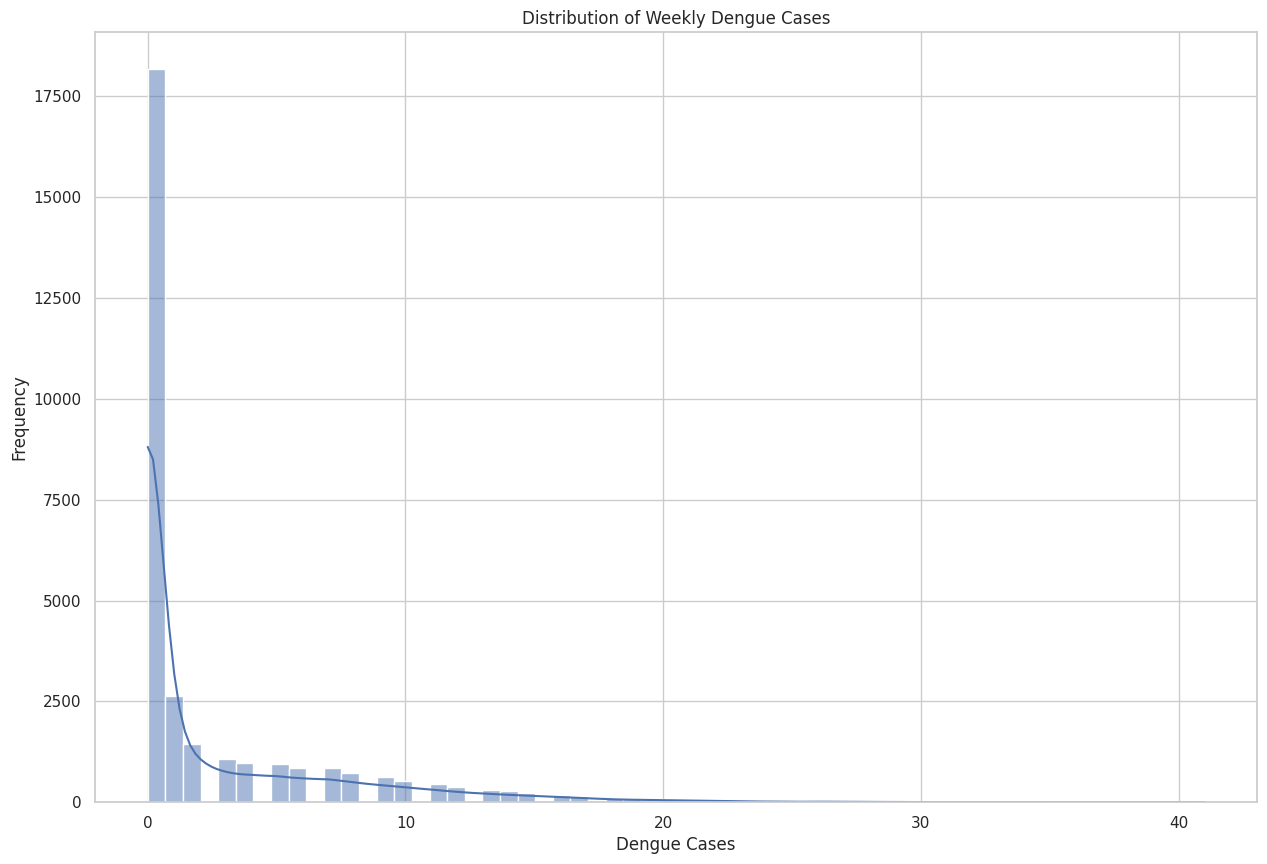

In [ ]:
plt.figure(figsize=(15, 10))

sns.histplot(
    data=df,
    x='dengue_cases',
    bins=60,
    kde=True
)

plt.title('Distribution of Weekly Dengue Cases')
plt.xlabel('Dengue Cases')
plt.ylabel('Frequency')

plt.show()

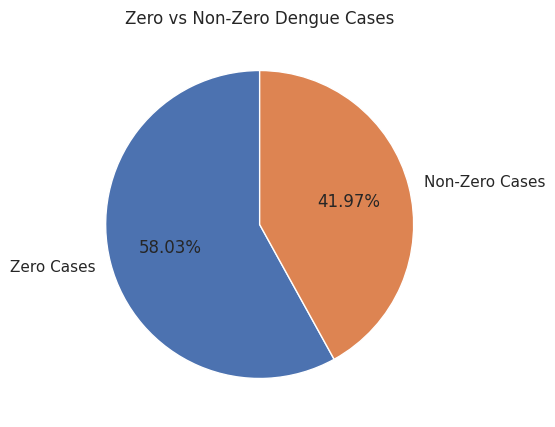

In [ ]:
case_counts = df['dengue_cases'].apply(
    lambda x: 'Zero Cases' if x == 0 else 'Non-Zero Cases'
).value_counts()

plt.figure(figsize=(7, 5))

plt.pie(
    case_counts,
    labels=case_counts.index,
    autopct='%1.2f%%',
    startangle=90
)

plt.title('Zero vs Non-Zero Dengue Cases')
plt.show()

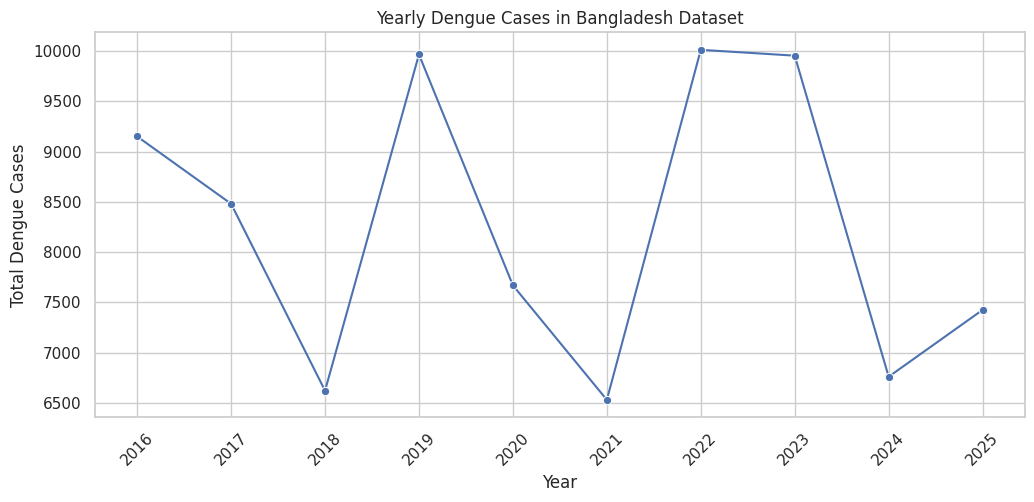

In [ ]:
yearly_cases = df.groupby(
    df['date'].dt.year
)['dengue_cases'].sum()

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=yearly_cases.index,
    y=yearly_cases.values,
    marker='o'
)

plt.title('Yearly Dengue Cases in Bangladesh Dataset')
plt.xlabel('Year')
plt.ylabel('Total Dengue Cases')

plt.xticks(yearly_cases.index, rotation=45)
plt.show()

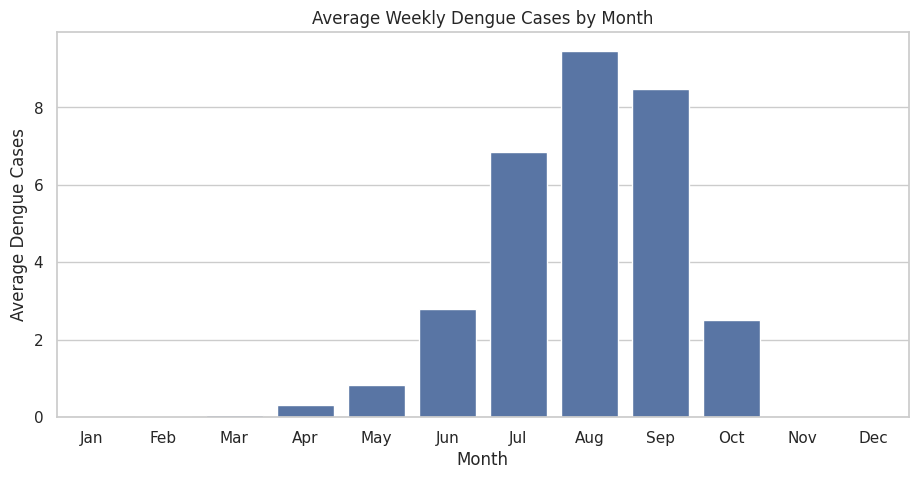

In [ ]:
monthly_cases = df.groupby(
    df['date'].dt.month
)['dengue_cases'].mean()

plt.figure(figsize=(11, 5))

sns.barplot(
    x=monthly_cases.index,
    y=monthly_cases.values
)

plt.title('Average Weekly Dengue Cases by Month')
plt.xlabel('Month')
plt.ylabel('Average Dengue Cases')

plt.xticks(
    ticks=range(12),
    labels=[
        'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
        'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
    ]
)

plt.show()

In [ ]:
city_cases = df.groupby(
    'city'
)['dengue_cases'].agg(['sum', 'mean', 'median'])

city_cases = city_cases.sort_values(
    by='mean',
    ascending=False
)

print(city_cases)

               sum      mean  median
city                                
Gazipur       8295  3.178161     0.0
Dhaka South  27193  2.604693     0.0
Dhaka North  27001  2.586303     0.0
Chattogram   13470  2.580460     0.0
Narayanganj   6613  2.533716     0.0


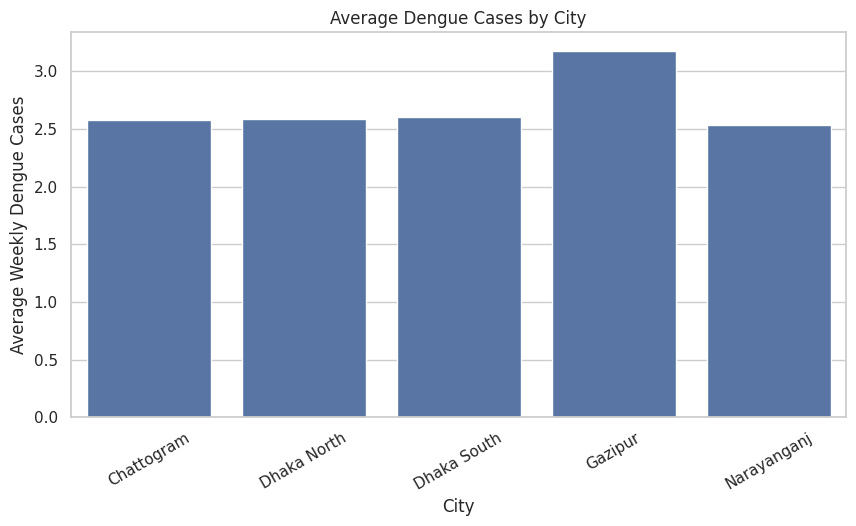

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='city',
    y='dengue_cases',
    estimator='mean',
    errorbar=None
)

plt.title('Average Dengue Cases by City')
plt.xlabel('City')
plt.ylabel('Average Weekly Dengue Cases')

plt.xticks(rotation=30)
plt.show()

In [ ]:
ward_cases = df.groupby(
    ['city', 'ward_id']
)['dengue_cases'].agg(
    total_cases='sum',
    avg_cases='mean',
    max_cases='max'
).reset_index()

ward_cases = ward_cases.sort_values(
    by='total_cases',
    ascending=False
)

ward_cases.head(15)

,city,ward_id,total_cases,avg_cases,max_cases
2,Chattogram,CCC_Ward_03,2117,4.055556,38
21,Dhaka North,DNCC_Ward_12,2085,3.994253,39
33,Dhaka South,DSCC_Ward_04,2032,3.892720,29
28,Dhaka North,DNCC_Ward_19,1961,3.756705,32
35,Dhaka South,DSCC_Ward_06,1926,3.689655,33
0,Chattogram,CCC_Ward_01,1915,3.668582,33
51,Gazipur,GCC_Ward_02,1891,3.622605,34
52,Gazipur,GCC_Ward_03,1857,3.557471,29
59,Narayanganj,NCC_Ward_05,1833,3.511494,27
27,Dhaka North,DNCC_Ward_18,1822,3.490421,32


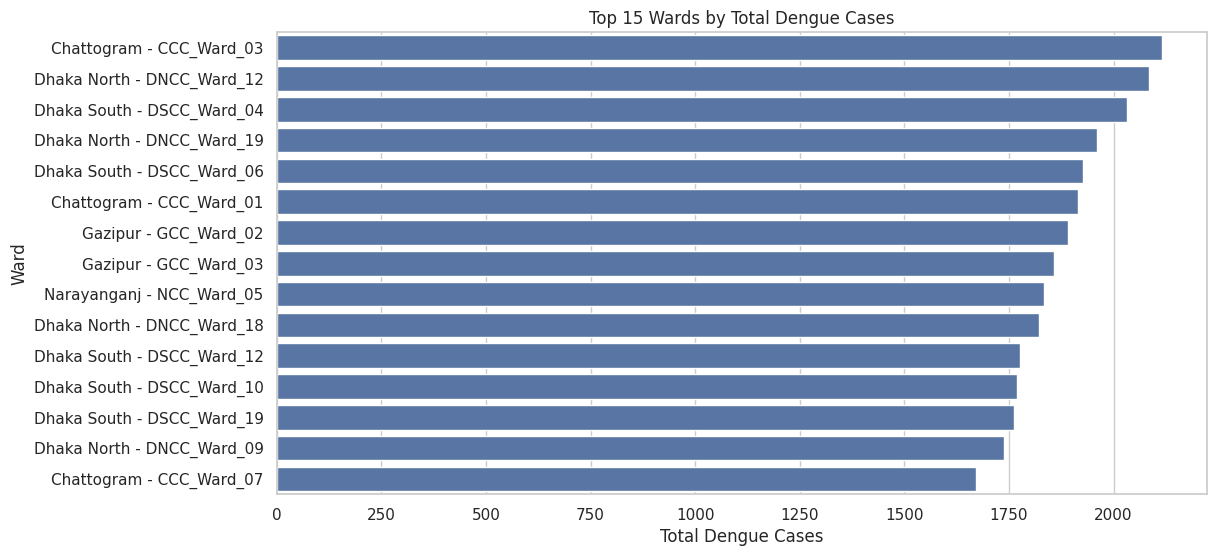

In [ ]:
top_wards = ward_cases.head(15).copy()

top_wards['ward_label'] = (
    top_wards['city'] + ' - ' + top_wards['ward_id'].astype(str)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_wards,
    x='total_cases',
    y='ward_label'
)

plt.title('Top 15 Wards by Total Dengue Cases')
plt.xlabel('Total Dengue Cases')
plt.ylabel('Ward')

plt.show()

In [ ]:
weather_columns = [
    'avg_temp_c',
    'max_temp_c',
    'min_temp_c',
    'rainfall_mm',
    'relative_humidity_pct'
]

df[weather_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
avg_temp_c,31320.0,26.922804,4.482042,15.74,22.8800,26.850,31.0225,37.51
max_temp_c,31320.0,31.889061,4.516627,23.12,27.8500,31.505,35.9900,40.79
min_temp_c,31320.0,21.949425,4.527965,13.06,18.0000,21.670,25.9700,31.64
rainfall_mm,31320.0,35.630268,50.237519,0.00,0.9200,8.370,59.4200,268.83
relative_humidity_pct,31320.0,71.176132,12.968610,41.84,60.4675,68.220,83.9800,99.00


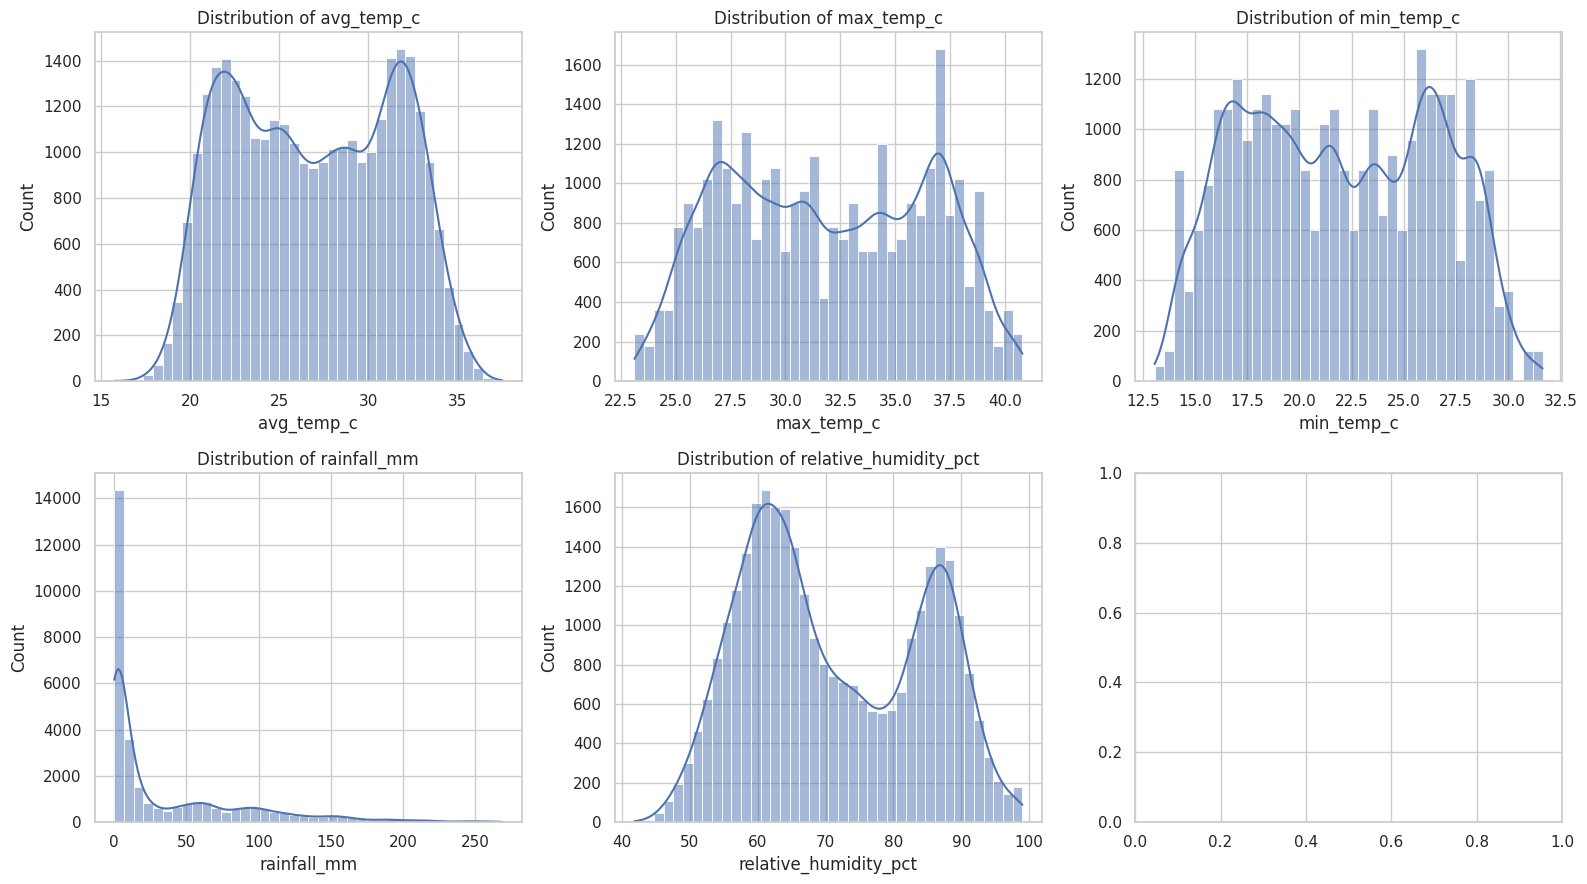

In [ ]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9)
)

for col, ax in zip(weather_columns, axes.flatten()):
    sns.histplot(
        df[col],
        kde=True,
        bins=40,
        ax=ax
    )

    ax.set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

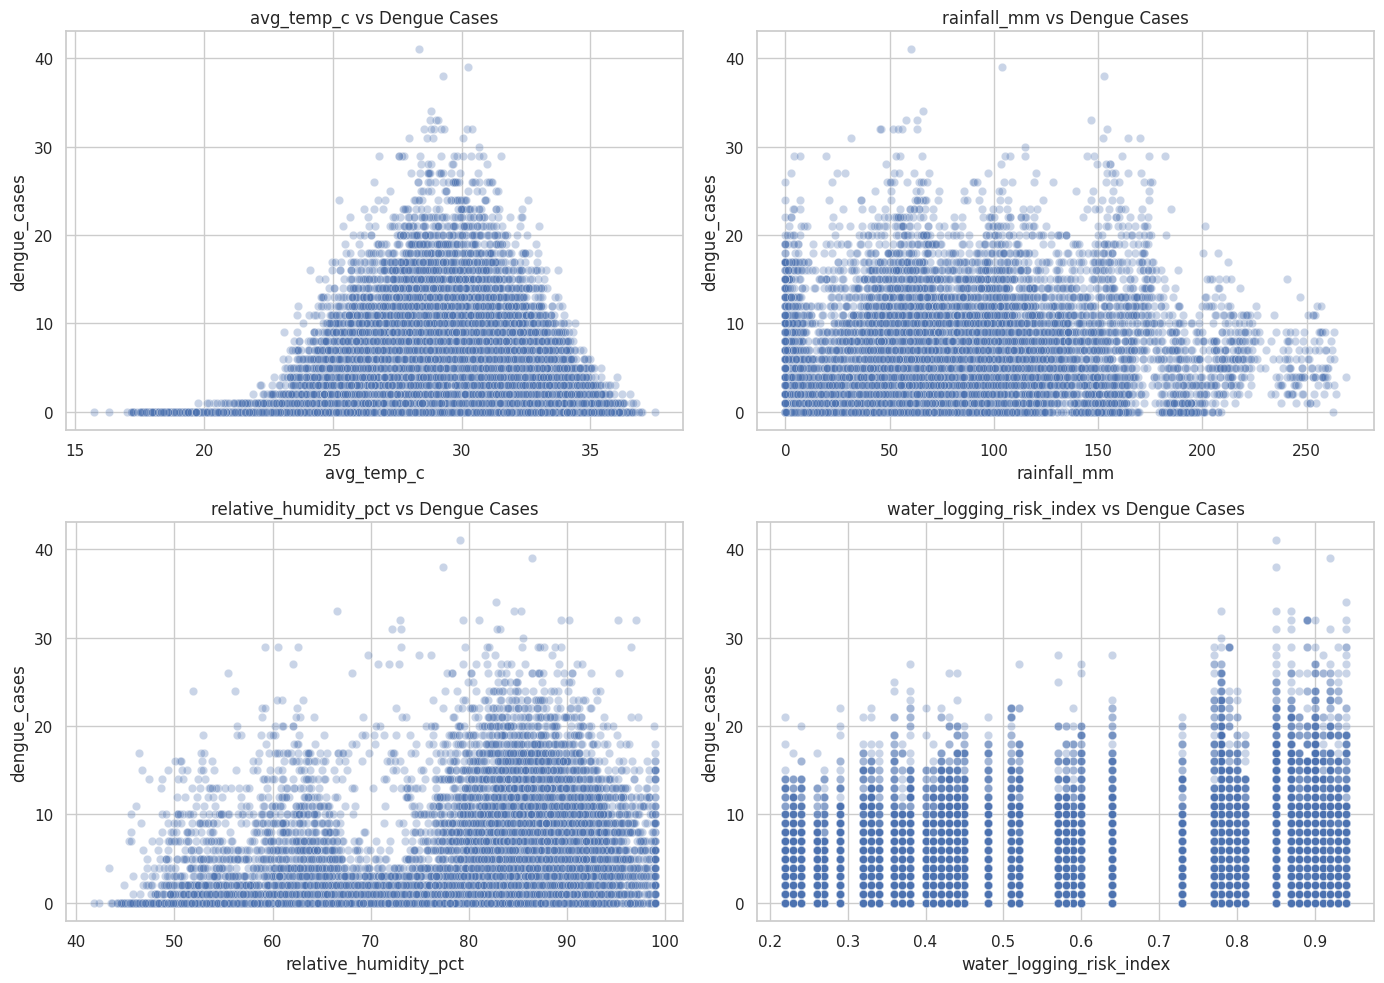

In [ ]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

features = [
    'avg_temp_c',
    'rainfall_mm',
    'relative_humidity_pct',
    'water_logging_risk_index'
]

for col, ax in zip(features, axes.flatten()):
    sns.scatterplot(
        data=df,
        x=col,
        y='dengue_cases',
        alpha=0.3,
        ax=ax
    )

    ax.set_title(f'{col} vs Dengue Cases')

plt.tight_layout()
plt.show()

In [ ]:
numerical_columns = [
    'population_density_sqkm',
    'water_logging_risk_index',
    'sanitation_score',
    'avg_temp_c',
    'max_temp_c',
    'min_temp_c',
    'rainfall_mm',
    'relative_humidity_pct',
    'dengue_cases'
]

correlation_matrix = df[numerical_columns].corr()

correlation_matrix

,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases
population_density_sqkm,1.000000e+00,6.968010e-02,-2.631844e-01,-0.000971,1.292129e-15,-8.358409e-16,0.000488,0.001307,0.086736
water_logging_risk_index,6.968010e-02,1.000000e+00,-5.861962e-02,0.000206,-2.081199e-15,7.264130e-16,-0.000603,0.000727,0.124765
sanitation_score,-2.631844e-01,-5.861962e-02,1.000000e+00,-0.000388,-5.088433e-16,1.211443e-15,0.000098,-0.001697,-0.060917
avg_temp_c,-9.708025e-04,2.060160e-04,-3.877097e-04,1.000000,9.730956e-01,9.721304e-01,0.537685,0.726965,0.335319
max_temp_c,1.292129e-15,-2.081199e-15,-5.088433e-16,0.973096,1.000000e+00,9.641488e-01,0.532962,0.724023,0.331619
min_temp_c,-8.358409e-16,7.264130e-16,1.211443e-15,0.972130,9.641488e-01,1.000000e+00,0.537430,0.725210,0.342334
rainfall_mm,4.881956e-04,-6.027618e-04,9.752301e-05,0.537685,5.329617e-01,5.374305e-01,1.000000,0.729890,0.531192
relative_humidity_pct,1.307041e-03,7.272148e-04,-1.696659e-03,0.726965,7.240231e-01,7.252102e-01,0.729890,1.000000,0.526834
dengue_cases,8.673577e-02,1.247645e-01,-6.091748e-02,0.335319,3.316188e-01,3.423338e-01,0.531192,0.526834,1.000000


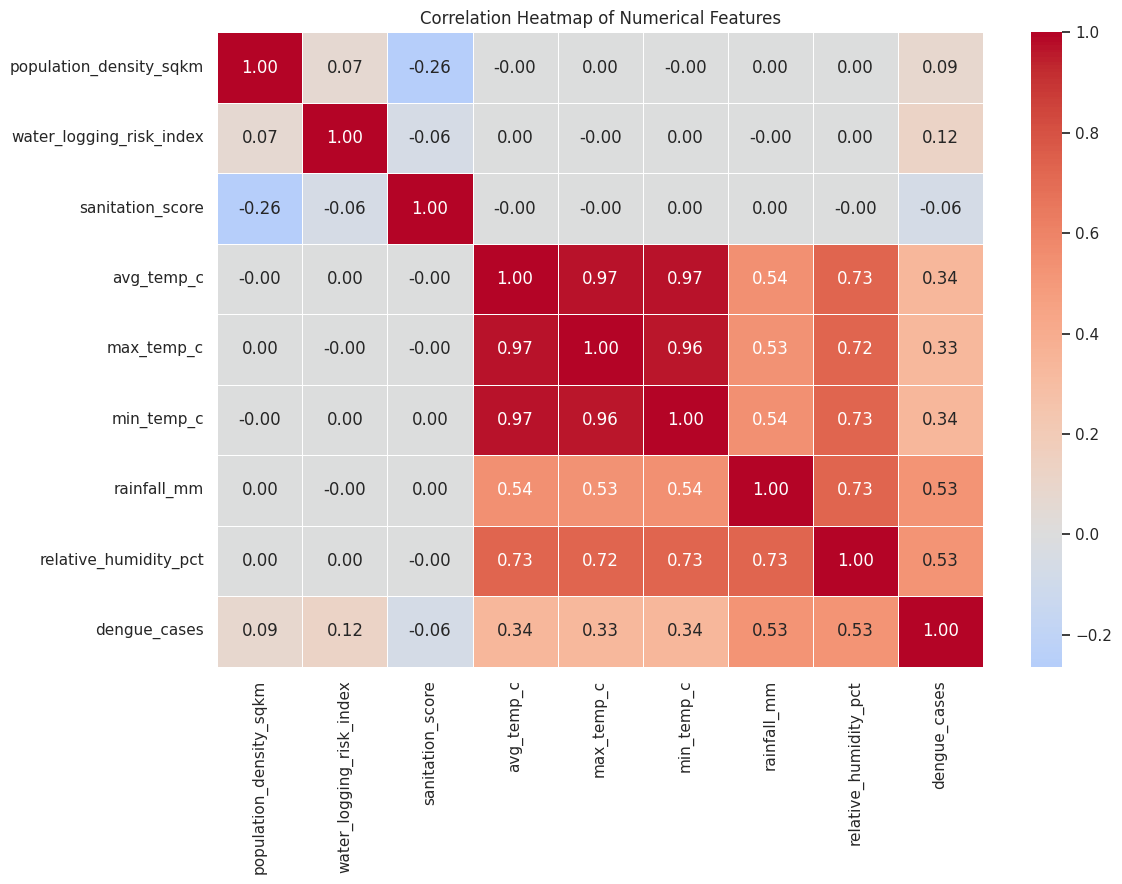

In [ ]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

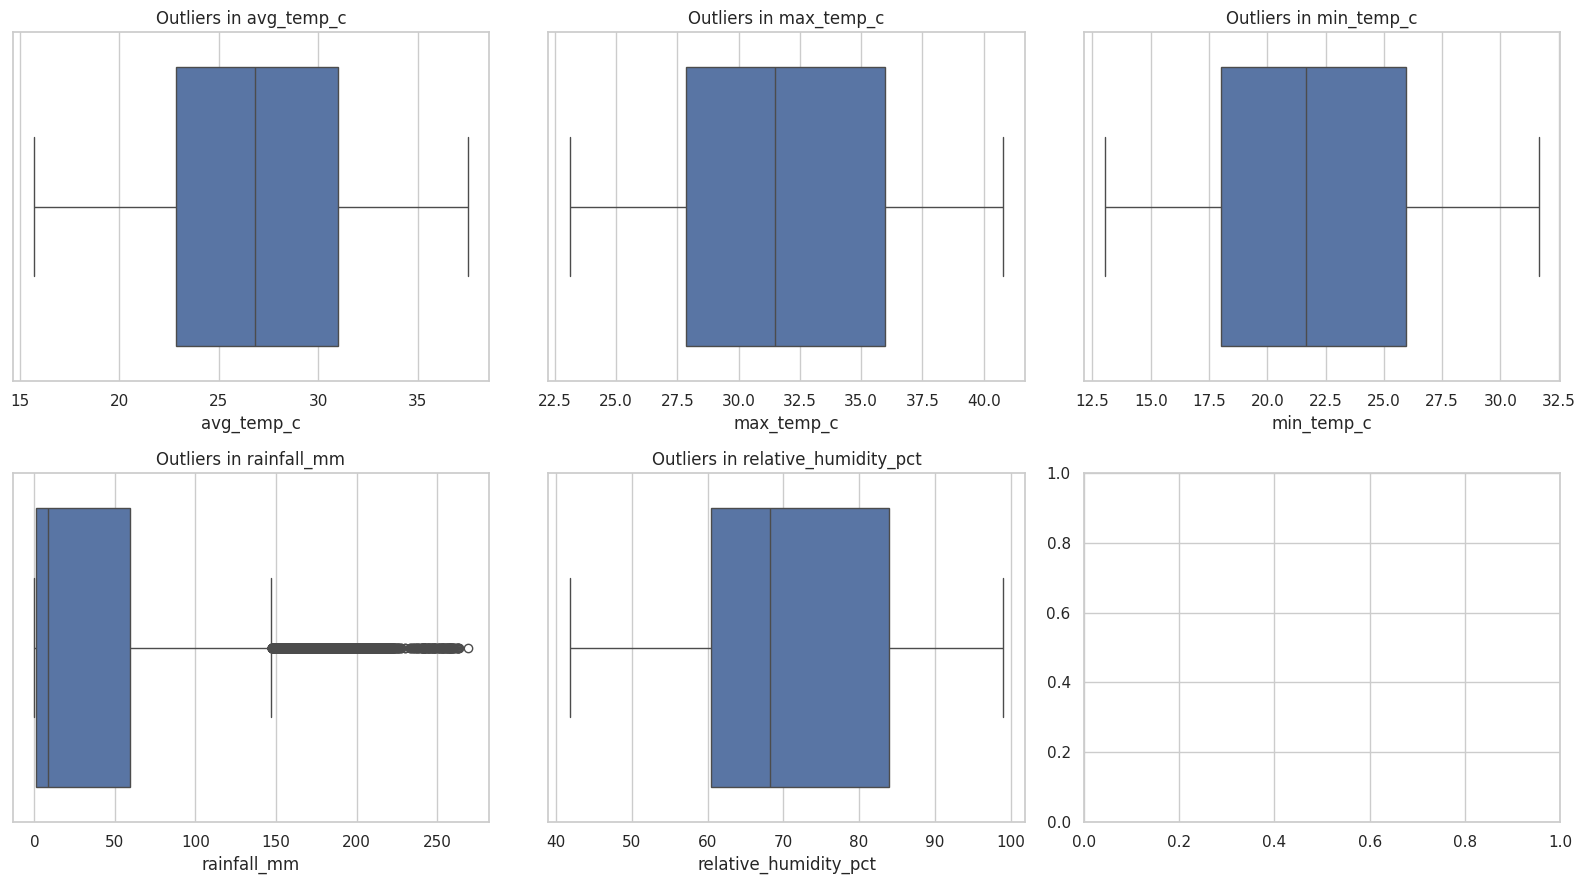

In [ ]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9)
)

for col, ax in zip(weather_columns, axes.flatten()):
    sns.boxplot(
        x=df[col],
        ax=ax
    )

    ax.set_title(f'Outliers in {col}')

plt.tight_layout()
plt.show()

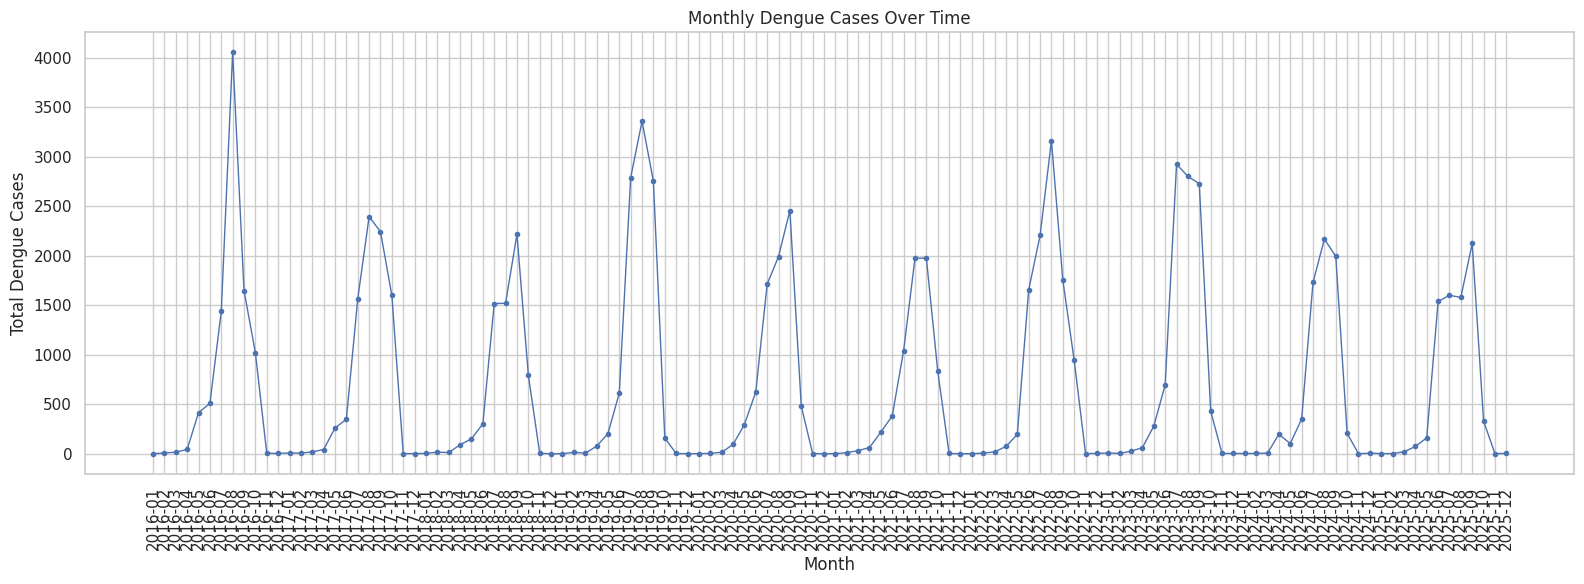

In [ ]:
df['year_month'] = df['date'].dt.to_period('M')

monthly_trend = df.groupby(
    'year_month'
)['dengue_cases'].sum()

plt.figure(figsize=(16, 6))

plt.plot(
    monthly_trend.index.astype(str),
    monthly_trend.values,
    marker='.',
    linewidth=1
)

plt.title('Monthly Dengue Cases Over Time')
plt.xlabel('Month')
plt.ylabel('Total Dengue Cases')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

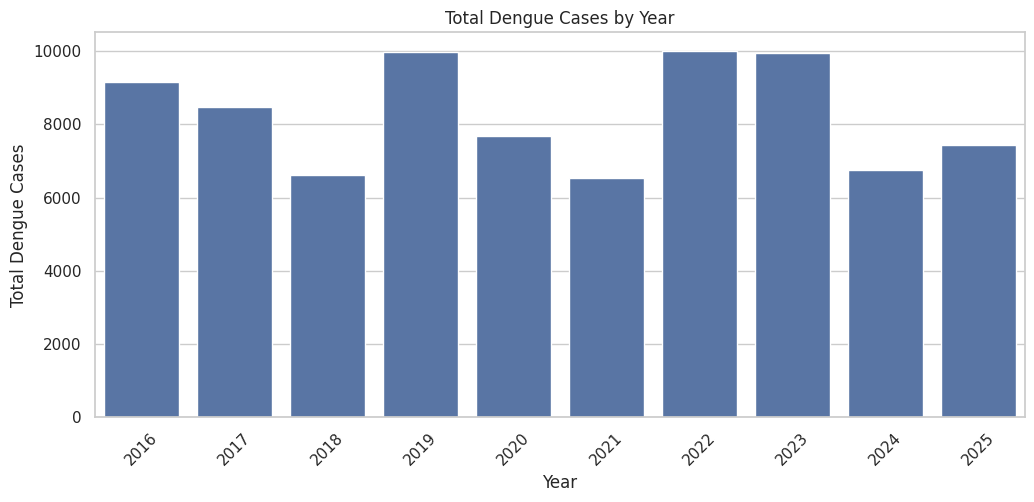

date
2022    10013
2019     9967
2023     9955
2016     9151
2017     8481
2020     7669
2025     7425
2024     6760
2018     6621
2021     6530
Name: dengue_cases, dtype: int64


In [ ]:
yearly_trend = df.groupby(
    df['date'].dt.year
)['dengue_cases'].sum()

plt.figure(figsize=(12, 5))

sns.barplot(
    x=yearly_trend.index,
    y=yearly_trend.values
)

plt.title('Total Dengue Cases by Year')
plt.xlabel('Year')
plt.ylabel('Total Dengue Cases')

plt.xticks(rotation=45)
plt.show()

print(yearly_trend.sort_values(ascending=False))

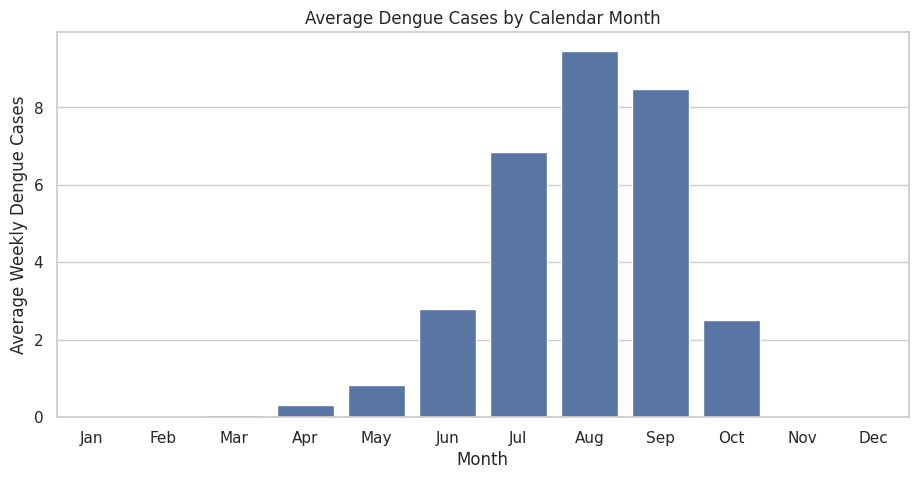

In [ ]:
df['month'] = df['date'].dt.month

monthly_seasonality = df.groupby(
    'month'
)['dengue_cases'].mean()

plt.figure(figsize=(11, 5))

sns.barplot(
    x=monthly_seasonality.index,
    y=monthly_seasonality.values
)

plt.title('Average Dengue Cases by Calendar Month')
plt.xlabel('Month')
plt.ylabel('Average Weekly Dengue Cases')

plt.xticks(
    range(12),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.show()

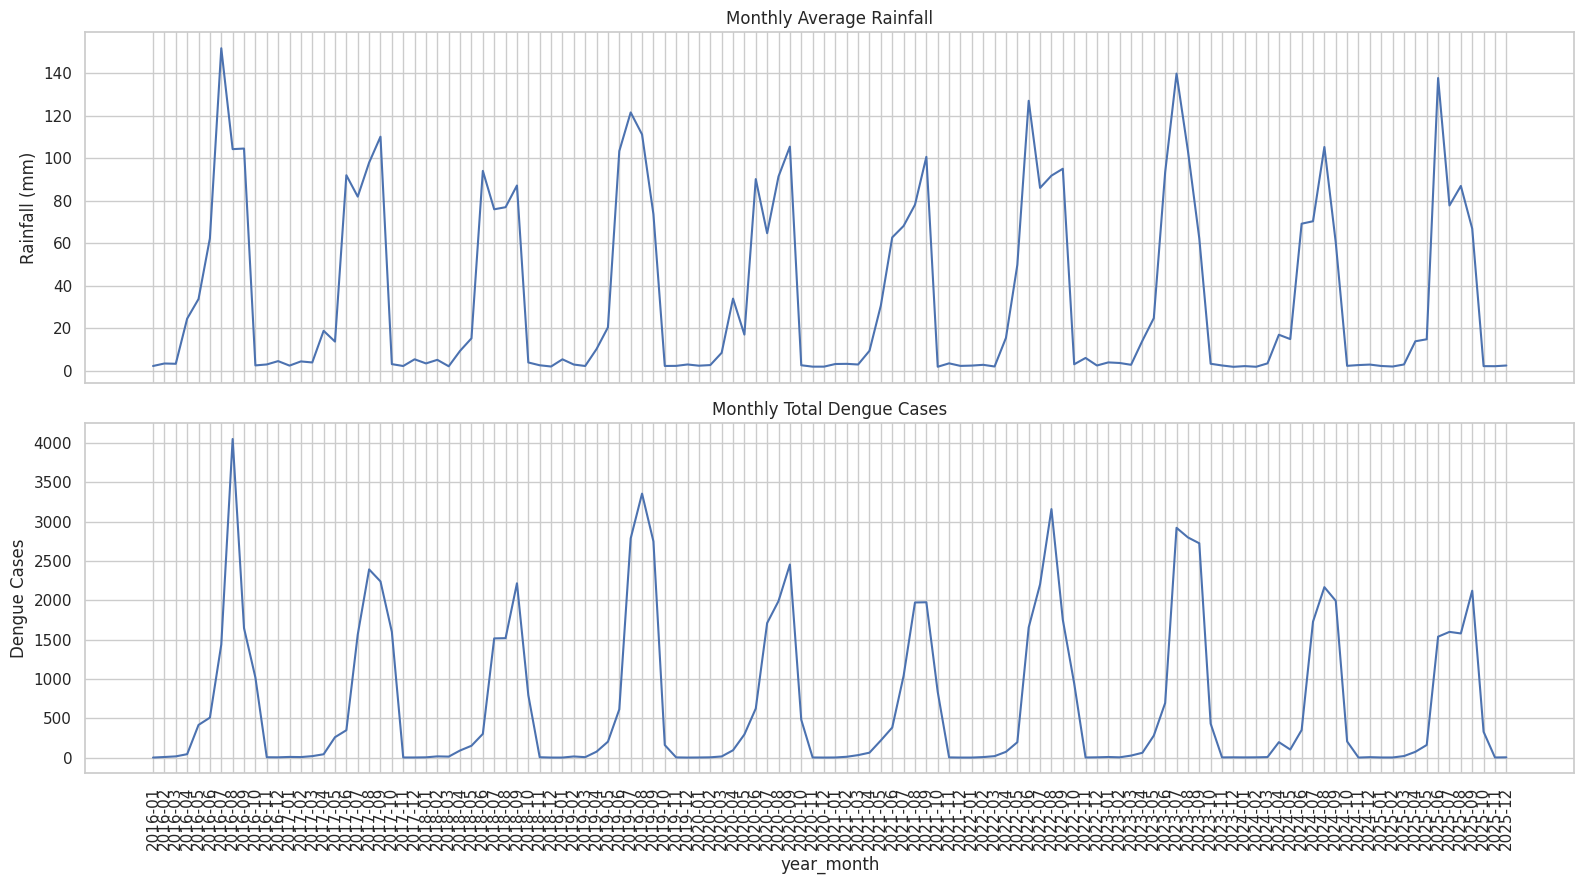

In [ ]:
monthly_weather = df.groupby(
    'year_month'
).agg(
    dengue_cases=('dengue_cases', 'sum'),
    rainfall_mm=('rainfall_mm', 'mean')
).reset_index()

monthly_weather['year_month'] = (
    monthly_weather['year_month'].astype(str)
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(16, 9),
    sharex=True
)

sns.lineplot(
    data=monthly_weather,
    x='year_month',
    y='rainfall_mm',
    ax=axes[0]
)

axes[0].set_title('Monthly Average Rainfall')
axes[0].set_ylabel('Rainfall (mm)')

sns.lineplot(
    data=monthly_weather,
    x='year_month',
    y='dengue_cases',
    ax=axes[1]
)

axes[1].set_title('Monthly Total Dengue Cases')
axes[1].set_ylabel('Dengue Cases')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
lag_features = [
    'rainfall_mm',
    'rainfall_lag_1w',
    'rainfall_lag_2w',
    'rainfall_lag_3w',
    'rainfall_lag_4w',
    'temp_lag_1w',
    'temp_lag_2w',
    'temp_lag_3w',
    'temp_lag_4w',
    'humidity_lag_1w',
    'humidity_lag_2w',
    'humidity_lag_3w',
    'humidity_lag_4w'
]

lag_correlation = df[
    lag_features + ['dengue_cases']
].corr()['dengue_cases'].drop('dengue_cases')

print(
    lag_correlation.sort_values(
        ascending=False
    )
)

rainfall_lag_3w    0.750070
rainfall_lag_4w    0.680672
rainfall_lag_2w    0.672189
humidity_lag_2w    0.660841
humidity_lag_3w    0.640487
humidity_lag_4w    0.622015
rainfall_lag_1w    0.591318
humidity_lag_1w    0.588592
temp_lag_4w        0.532237
rainfall_mm        0.531192
temp_lag_3w        0.497977
temp_lag_2w        0.450362
temp_lag_1w        0.408148
Name: dengue_cases, dtype: float64


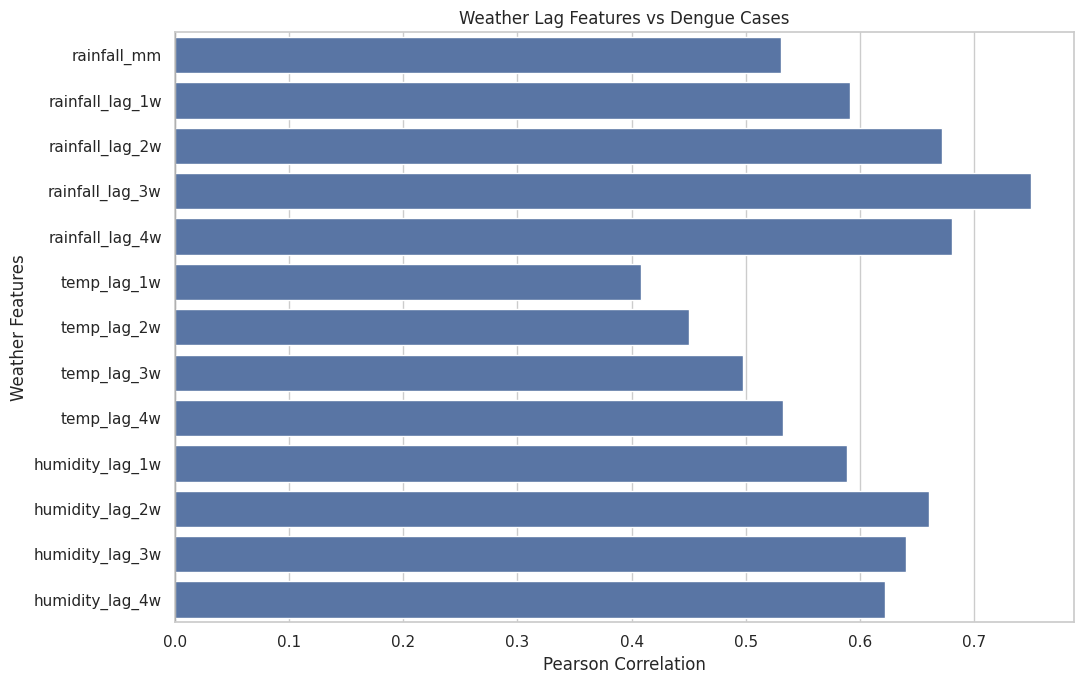

In [ ]:
plt.figure(figsize=(11, 7))

sns.barplot(
    x=lag_correlation.values,
    y=lag_correlation.index
)

plt.title('Weather Lag Features vs Dengue Cases')
plt.xlabel('Pearson Correlation')
plt.ylabel('Weather Features')

plt.axvline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()

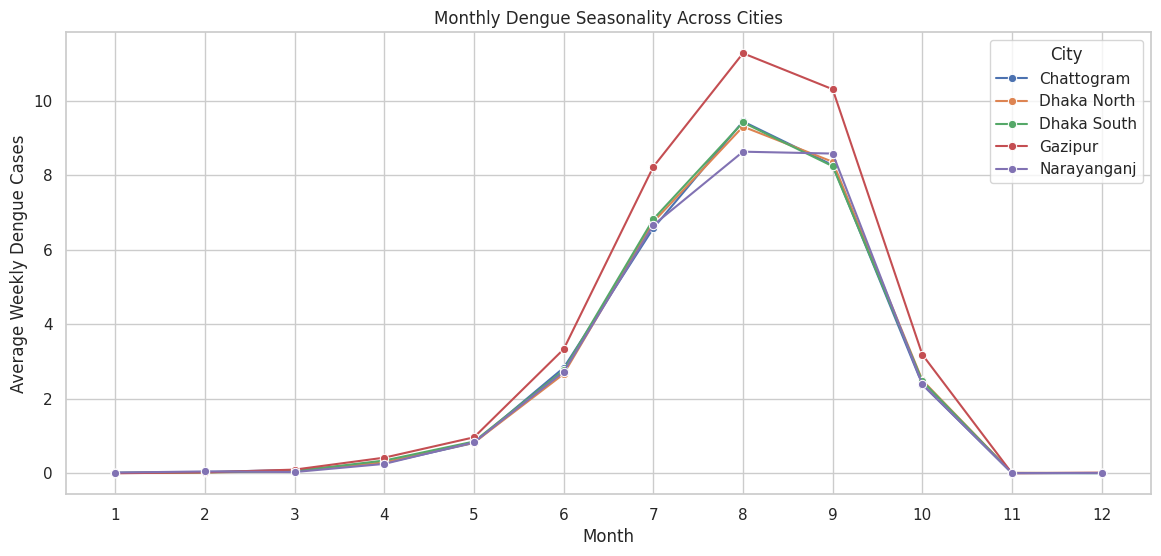

In [ ]:
city_monthly = df.groupby(
    ['city', 'month']
)['dengue_cases'].mean().reset_index()

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=city_monthly,
    x='month',
    y='dengue_cases',
    hue='city',
    marker='o'
)

plt.title('Monthly Dengue Seasonality Across Cities')
plt.xlabel('Month')
plt.ylabel('Average Weekly Dengue Cases')

plt.xticks(range(1, 13))
plt.legend(title='City')
plt.show()

In [ ]:
engineered_columns = [
    'rainfall_lag_1w',
    'rainfall_lag_2w',
    'rainfall_lag_3w',
    'rainfall_lag_4w',
    'temp_lag_1w',
    'temp_lag_2w',
    'temp_lag_3w',
    'temp_lag_4w',
    'humidity_lag_1w',
    'humidity_lag_2w',
    'humidity_lag_3w',
    'humidity_lag_4w',
    'rain_roll4w_sum'
]

df[engineered_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
rainfall_lag_1w,31260.0,35.695073,50.263756,0.00,0.9400,8.410,59.4925,268.83
rainfall_lag_2w,31200.0,35.757013,50.291910,0.00,0.9475,8.450,59.5700,268.83
rainfall_lag_3w,31140.0,35.821870,50.318359,0.00,0.9575,8.490,59.7200,268.83
rainfall_lag_4w,31080.0,35.886513,50.345145,0.00,0.9700,8.530,59.7875,268.83
temp_lag_1w,31260.0,26.931895,4.481420,15.74,22.9000,26.860,31.0325,37.51
temp_lag_2w,31200.0,26.941298,4.480510,15.74,22.9100,26.880,31.0400,37.51
temp_lag_3w,31140.0,26.952628,4.477312,15.74,22.9400,26.900,31.0400,37.51
temp_lag_4w,31080.0,26.964545,4.473328,15.74,22.9500,26.920,31.0500,37.51
humidity_lag_1w,31260.0,71.202331,12.966804,41.84,60.4900,68.260,83.9900,99.00
humidity_lag_2w,31200.0,71.227241,12.966335,41.84,60.5200,68.300,84.0100,99.00


In [ ]:
# Independently verify rainfall lag
df = df.sort_values(
    ['ward_id', 'date']
).reset_index(drop=True)

expected_lag = df.groupby('ward_id')['rainfall_mm'].shift(3)

comparison = pd.DataFrame({
    'existing': df['rainfall_lag_3w'],
    'expected': expected_lag
})

print(
    "Lag calculation matches:",
    np.allclose(
        comparison['existing'],
        comparison['expected'],
        equal_nan=True
    )
)

Lag calculation matches: True


In [ ]:
df = df.sort_values(
    ['ward_id', 'date']
).reset_index(drop=True)

grouped = df.groupby('ward_id')

df['rain_roll2w_sum'] = grouped['rainfall_mm'].transform(
    lambda x: x.shift(1).rolling(2).sum()
)

df['rain_roll3w_sum'] = grouped['rainfall_mm'].transform(
    lambda x: x.shift(1).rolling(3).sum()
)

df['rain_roll4w_sum'] = grouped['rainfall_mm'].transform(
    lambda x: x.shift(1).rolling(4).sum()
)

In [ ]:
df['month'] = df['date'].dt.month

df['month_sin'] = np.sin(
    2 * np.pi * df['month'] / 12
)

df['month_cos'] = np.cos(
    2 * np.pi * df['month'] / 12
)

In [ ]:
grouped = df.groupby('ward_id')['dengue_cases']

df['future_dengue_cases_2_4w'] = (
    grouped.shift(-2) +
    grouped.shift(-3) +
    grouped.shift(-4)
)

In [ ]:
df['future_dengue_cases_2_4w'].describe()



,future_dengue_cases_2_4w
count,31080.000000
mean,7.970174
std,12.500664
min,0.000000
25%,0.000000
50%,1.000000
75%,13.000000
max,92.000000


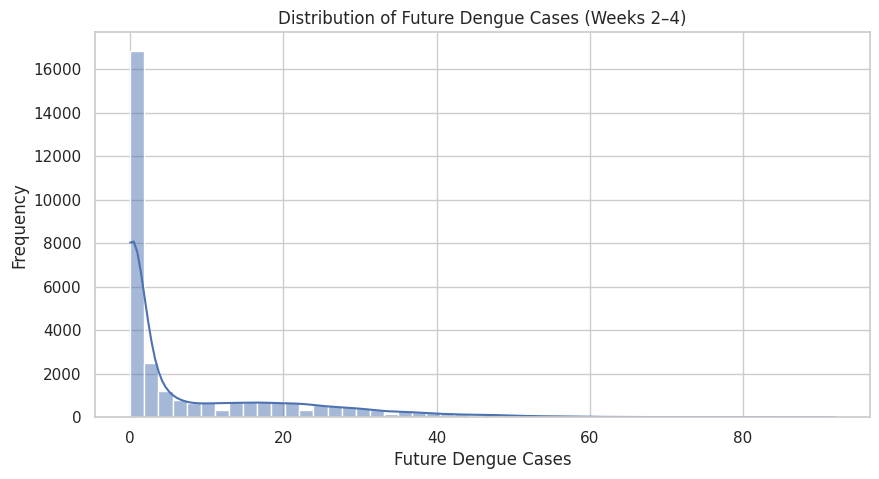

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['future_dengue_cases_2_4w'].dropna(),
    bins=50,
    kde=True
)

plt.title('Distribution of Future Dengue Cases (Weeks 2–4)')
plt.xlabel('Future Dengue Cases')
plt.ylabel('Frequency')

plt.show()

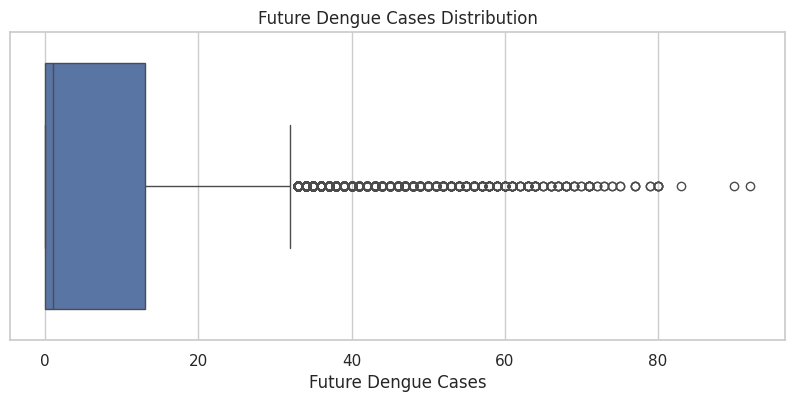

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df['future_dengue_cases_2_4w']
)

plt.title('Future Dengue Cases Distribution')
plt.xlabel('Future Dengue Cases')

plt.show()

future_dengue_cases_2_4w
Non-Zero Cases    16970
Zero Cases        14350
Name: count, dtype: int64


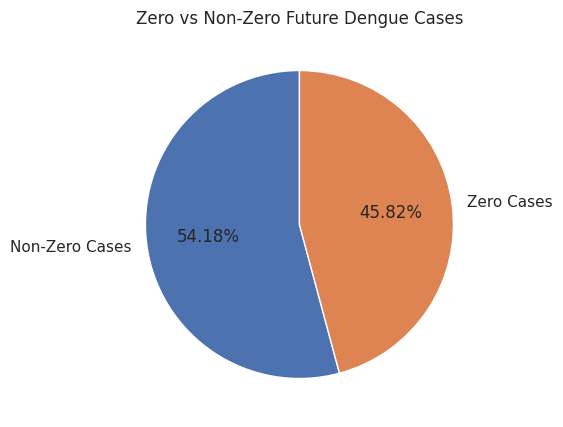

In [ ]:
future_counts = df[
    'future_dengue_cases_2_4w'
].apply(
    lambda x: 'Zero Cases' if x == 0
    else 'Non-Zero Cases'
).value_counts()

print(future_counts)

plt.figure(figsize=(7, 5))

plt.pie(
    future_counts,
    labels=future_counts.index,
    autopct='%1.2f%%',
    startangle=90
)

plt.title('Zero vs Non-Zero Future Dengue Cases')
plt.show()

In [ ]:
check_ward = df['ward_id'].iloc[100]
check_date = df['date'].iloc[100]

sample = df[
    (df['ward_id'] == check_ward) &
    (df['date'] >= check_date)
].sort_values('date').head(5)

print(
    sample[
        ['ward_id', 'date', 'dengue_cases',
         'future_dengue_cases_2_4w']
    ]
)

         ward_id       date  dengue_cases  future_dengue_cases_2_4w
100  CCC_Ward_01 2017-12-04             0                       0.0
101  CCC_Ward_01 2017-12-11             0                       0.0
102  CCC_Ward_01 2017-12-18             0                       0.0
103  CCC_Ward_01 2017-12-25             0                       0.0
104  CCC_Ward_01 2018-01-01             0                       0.0


In [ ]:
valid_target = df['future_dengue_cases_2_4w'].dropna()

future_counts = pd.Series({
    'Zero Cases': (valid_target == 0).sum(),
    'Non-Zero Cases': (valid_target > 0).sum()
})

print(future_counts)

print("\nTotal valid observations:", len(valid_target))

Zero Cases        14350
Non-Zero Cases    16730
dtype: int64

Total valid observations: 31080


In [ ]:
df = df.sort_values(
    ['ward_id', 'date']
).reset_index(drop=True)

grouped = df.groupby('ward_id')

# Historical dengue case features
for lag in range(1, 5):
    df[f'dengue_lag_{lag}w'] = (
        grouped['dengue_cases'].shift(lag)
    )

# Historical rolling average
df['dengue_roll4w_mean'] = grouped[
    'dengue_cases'
].transform(
    lambda x: x.shift(1).rolling(4).mean()
)

In [ ]:
dengue_features = [
    'dengue_lag_1w',
    'dengue_lag_2w',
    'dengue_lag_3w',
    'dengue_lag_4w',
    'dengue_roll4w_mean'
]

df[dengue_features].describe().T

,count,mean,std,min,25%,50%,75%,max
dengue_lag_1w,31260.0,2.641427,4.610723,0.0,0.0,0.00,4.0,41.00
dengue_lag_2w,31200.0,2.646474,4.613712,0.0,0.0,0.00,4.0,41.00
dengue_lag_3w,31140.0,2.651574,4.616691,0.0,0.0,0.00,4.0,41.00
dengue_lag_4w,31080.0,2.656660,4.619689,0.0,0.0,0.00,4.0,41.00
dengue_roll4w_mean,31080.0,2.656692,4.054530,0.0,0.0,0.25,4.5,26.25


In [ ]:
numeric_features = [
    # Environmental
    'population_density_sqkm',
    'water_logging_risk_index',
    'sanitation_score',

    # Current weather
    'avg_temp_c',
    'max_temp_c',
    'min_temp_c',
    'rainfall_mm',
    'relative_humidity_pct',

    # Historical rainfall
    'rainfall_lag_1w',
    'rainfall_lag_2w',
    'rainfall_lag_3w',
    'rainfall_lag_4w',
    'rain_roll2w_sum',
    'rain_roll3w_sum',
    'rain_roll4w_sum',

    # Historical temperature
    'temp_lag_1w',
    'temp_lag_2w',
    'temp_lag_3w',
    'temp_lag_4w',

    # Historical humidity
    'humidity_lag_1w',
    'humidity_lag_2w',
    'humidity_lag_3w',
    'humidity_lag_4w',

    # Historical dengue
    'dengue_lag_1w',
    'dengue_lag_2w',
    'dengue_lag_3w',
    'dengue_lag_4w',
    'dengue_roll4w_mean',

    # Seasonality
    'month_sin',
    'month_cos'
]

categorical_features = [
    'city',
    'ward_id'
]

target = 'future_dengue_cases_2_4w'

feature_columns = numeric_features + categorical_features

print("Total numerical features:", len(numeric_features))
print("Total categorical features:", len(categorical_features))
print("Total input features:", len(feature_columns))

Total numerical features: 30
Total categorical features: 2
Total input features: 32


In [ ]:
missing_features = [
    col for col in feature_columns + [target]
    if col not in df.columns
]

print("Missing feature columns:", missing_features)

Missing feature columns: []


In [ ]:
model_df = df[
    ['date'] + feature_columns + [target]
].copy()

print("Before cleaning:", model_df.shape)

model_df = model_df.replace(
    [np.inf, -np.inf],
    np.nan
)

model_df = model_df.dropna(
    subset=feature_columns + [target]
).reset_index(drop=True)

print("After cleaning:", model_df.shape)

print(
    "Remaining missing values:",
    model_df[feature_columns + [target]].isnull().sum().sum()
)

Before cleaning: (31320, 34)
After cleaning: (30840, 34)
Remaining missing values: 0


In [ ]:
unique_dates = np.sort(
    model_df['date'].unique()
)

train_cutoff = pd.Timestamp(
    unique_dates[int(len(unique_dates) * 0.70)]
)

val_cutoff = pd.Timestamp(
    unique_dates[int(len(unique_dates) * 0.85)]
)

print("Training cutoff:", train_cutoff)
print("Validation cutoff:", val_cutoff)

Training cutoff: 2022-12-19 00:00:00
Validation cutoff: 2024-06-10 00:00:00


In [ ]:
# Training: future target must finish before train cutoff
train_df = model_df[
    model_df['date'] <= train_cutoff - pd.Timedelta(weeks=4)
].copy()

# Validation: predictions occur after training cutoff,
# and their future targets finish before validation cutoff
val_df = model_df[
    (model_df['date'] > train_cutoff) &
    (model_df['date'] <= val_cutoff - pd.Timedelta(weeks=4))
].copy()

# Testing: latest unseen period
test_df = model_df[
    model_df['date'] > val_cutoff
].copy()

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (21360, 34)
Validation shape: (4380, 34)
Testing shape: (4620, 34)


In [ ]:
X_train = train_df[feature_columns]
y_train = train_df[target]

X_val = val_df[feature_columns]
y_val = val_df[target]

X_test = test_df[feature_columns]
y_test = test_df[target]

In [ ]:
for name, data in [
    ('Training', train_df),
    ('Validation', val_df),
    ('Testing', test_df)
]:
    print(f"\n{name}")
    print("Start:", data['date'].min())
    print("End:", data['date'].max())
    print("Rows:", len(data))


Training
Start: 2016-02-01 00:00:00
End: 2022-11-21 00:00:00
Rows: 21360

Validation
Start: 2022-12-26 00:00:00
End: 2024-05-13 00:00:00
Rows: 4380

Testing
Start: 2024-06-17 00:00:00
End: 2025-12-01 00:00:00
Rows: 4620


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)



In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            'passthrough',
            numeric_features
        ),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ]
)

In [ ]:
models = {
    'Dummy Regressor': DummyRegressor(
        strategy='mean'
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    'Extra Trees': ExtraTreesRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    'Hist Gradient Boosting': HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )
}

In [ ]:
results = []
trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_val)

    # Dengue cases cannot be negative
    predictions = np.maximum(predictions, 0)

    mae = mean_absolute_error(
        y_val,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_val, predictions)
    )

    r2 = r2_score(
        y_val,
        predictions
    )

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

    trained_models[name] = pipeline

    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R2: {r2:.4f}")
    print("-" * 40)

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='MAE'
)

results_df

Training Dummy Regressor...
MAE: 10.2024
RMSE: 13.4561
R2: -0.0072
----------------------------------------
Training Random Forest...
MAE: 2.5142
RMSE: 5.3951
R2: 0.8381
----------------------------------------
Training Extra Trees...
MAE: 2.2503
RMSE: 4.6331
R2: 0.8806
----------------------------------------
Training Hist Gradient Boosting...
MAE: 2.2197
RMSE: 4.5640
R2: 0.8841
----------------------------------------


,Model,MAE,RMSE,R2
3,Hist Gradient Boosting,2.219653,4.563972,0.884126
2,Extra Trees,2.250312,4.633133,0.880588
1,Random Forest,2.514238,5.395065,0.838083
0,Dummy Regressor,10.202386,13.456078,-0.007249


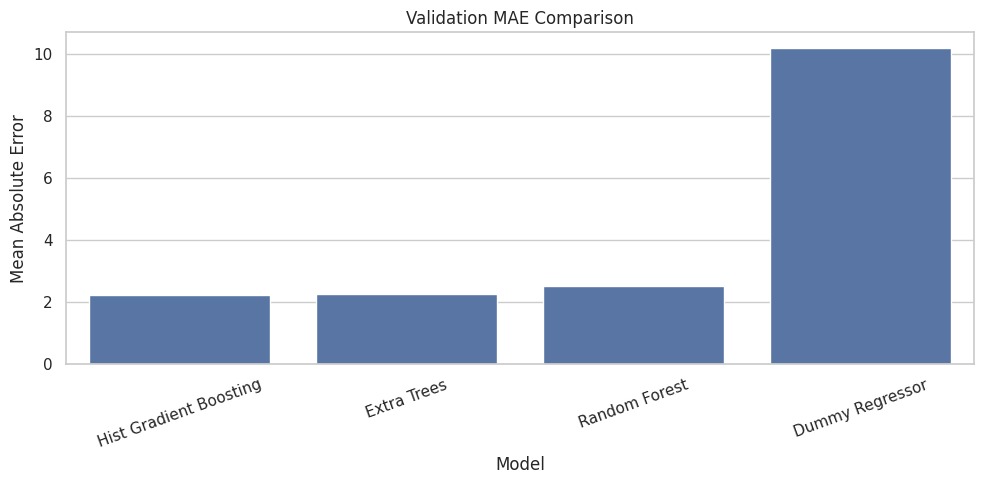

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='MAE'
)

plt.title('Validation MAE Comparison')
plt.xlabel('Model')
plt.ylabel('Mean Absolute Error')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
best_model = trained_models['Hist Gradient Boosting']

val_predictions = best_model.predict(X_val)

val_predictions = np.maximum(
    val_predictions,
    0
)

evaluation_df = pd.DataFrame({
    'Actual': y_val.values,
    'Predicted': val_predictions
})

evaluation_df['Error'] = (
    evaluation_df['Actual'] -
    evaluation_df['Predicted']
)

evaluation_df['Absolute_Error'] = (
    evaluation_df['Error'].abs()
)

evaluation_df.head(10)

,Actual,Predicted,Error,Absolute_Error
0,0.0,0.120924,-0.120924,0.120924
1,0.0,0.218431,-0.218431,0.218431
2,0.0,0.161822,-0.161822,0.161822
3,0.0,0.120924,-0.120924,0.120924
4,0.0,0.120924,-0.120924,0.120924
5,0.0,0.120924,-0.120924,0.120924
6,0.0,0.174240,-0.174240,0.174240
7,0.0,0.126512,-0.126512,0.126512
8,0.0,0.126512,-0.126512,0.126512
9,0.0,0.174240,-0.174240,0.174240


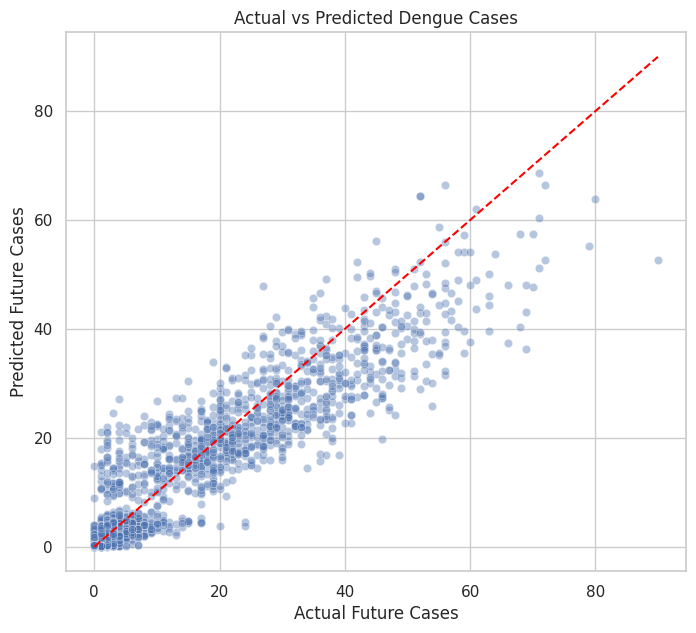

In [ ]:
plt.figure(figsize=(8, 7))

sns.scatterplot(
    data=evaluation_df,
    x='Actual',
    y='Predicted',
    alpha=0.4
)

max_value = max(
    evaluation_df['Actual'].max(),
    evaluation_df['Predicted'].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle='--',
    color='red'
)

plt.title('Actual vs Predicted Dengue Cases')
plt.xlabel('Actual Future Cases')
plt.ylabel('Predicted Future Cases')

plt.show()

In [ ]:
evaluation_df['Risk_Group'] = pd.cut(
    evaluation_df['Actual'],
    bins=[-0.001, 1, 13, 30, np.inf],
    labels=[
        'Zero–1 Cases',
        '2–13 Cases',
        '14–30 Cases',
        'Above 30 Cases'
    ]
)

risk_performance = evaluation_df.groupby(
    'Risk_Group',
    observed=False
).apply(
    lambda group: pd.Series({
        'Samples': len(group),
        'MAE': mean_absolute_error(
            group['Actual'],
            group['Predicted']
        ),
        'RMSE': np.sqrt(
            mean_squared_error(
                group['Actual'],
                group['Predicted']
            )
        ),
        'Mean Actual': group['Actual'].mean(),
        'Mean Predicted': group['Predicted'].mean()
    })
).reset_index()

risk_performance

,Risk_Group,Samples,MAE,RMSE,Mean Actual,Mean Predicted
0,Zero–1 Cases,2627.0,0.421957,1.172451,0.149220,0.451215
1,2–13 Cases,915.0,3.037117,4.714702,4.544262,5.244399
2,14–30 Cases,460.0,4.757345,5.957027,21.819565,20.491715
3,Above 30 Cases,378.0,9.646187,11.611078,43.267196,34.959566


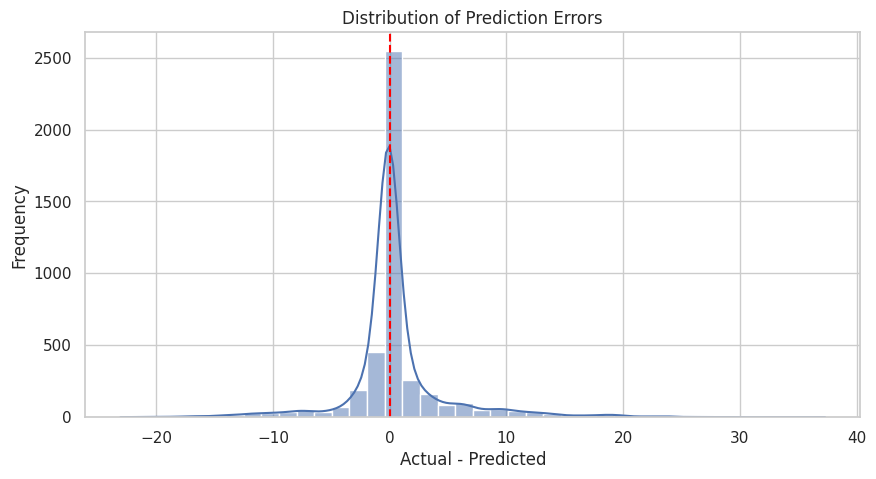

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    evaluation_df['Error'],
    bins=40,
    kde=True
)

plt.axvline(
    0,
    color='red',
    linestyle='--'
)

plt.title('Distribution of Prediction Errors')
plt.xlabel('Actual - Predicted')
plt.ylabel('Frequency')

plt.show()

In [ ]:
!pip install -q xgboost


In [ ]:
from xgboost import XGBRegressor

In [ ]:
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2,
    objective='reg:squarederror',
    eval_metric='rmse',
    random_state=42,
    n_jobs=-1
)

In [ ]:
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', xgb_model)
])

In [ ]:
print("Training XGBoost...")

xgb_pipeline.fit(
    X_train,
    y_train
)

print("Training completed!")

Training XGBoost...
Training completed!


In [ ]:
xgb_predictions = xgb_pipeline.predict(X_val)

xgb_predictions = np.maximum(
    xgb_predictions,
    0
)

xgb_mae = mean_absolute_error(
    y_val,
    xgb_predictions
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        xgb_predictions
    )
)

xgb_r2 = r2_score(
    y_val,
    xgb_predictions
)

print("XGBoost Results")
print("-" * 35)

print(f"MAE:  {xgb_mae:.4f}")
print(f"RMSE: {xgb_rmse:.4f}")
print(f"R2:   {xgb_r2:.4f}")

XGBoost Results
-----------------------------------
MAE:  2.1371
RMSE: 4.3730
R2:   0.8936


In [ ]:
xgb_result = pd.DataFrame([{
    'Model': 'XGBoost',
    'MAE': xgb_mae,
    'RMSE': xgb_rmse,
    'R2': xgb_r2
}])

all_results = pd.concat(
    [results_df, xgb_result],
    ignore_index=True
)

all_results = all_results.sort_values(
    by='MAE'
).reset_index(drop=True)

all_results

,Model,MAE,RMSE,R2
0,XGBoost,2.137119,4.372975,0.893622
1,Hist Gradient Boosting,2.219653,4.563972,0.884126
2,Extra Trees,2.250312,4.633133,0.880588
3,Random Forest,2.514238,5.395065,0.838083
4,Dummy Regressor,10.202386,13.456078,-0.007249


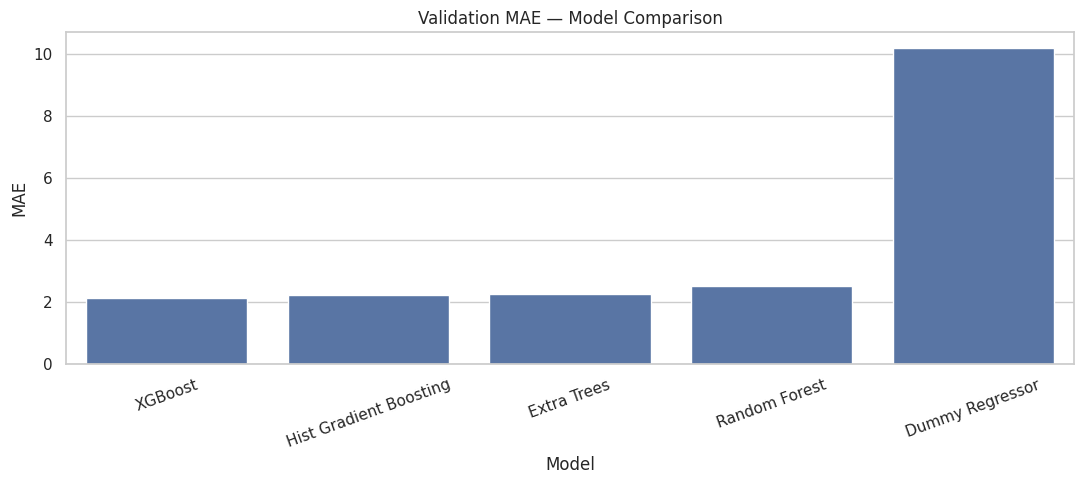

In [ ]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=all_results,
    x='Model',
    y='MAE'
)

plt.title('Validation MAE — Model Comparison')
plt.xlabel('Model')
plt.ylabel('MAE')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
xgb_evaluation = pd.DataFrame({
    'Actual': y_val.values,
    'Predicted': xgb_predictions
})

xgb_evaluation['Risk_Group'] = pd.cut(
    xgb_evaluation['Actual'],
    bins=[-0.001, 1, 13, 30, np.inf],
    labels=[
        'Zero–1 Cases',
        '2–13 Cases',
        '14–30 Cases',
        'Above 30 Cases'
    ]
)

xgb_risk_performance = xgb_evaluation.groupby(
    'Risk_Group',
    observed=False
).apply(
    lambda group: pd.Series({
        'Samples': len(group),
        'MAE': mean_absolute_error(
            group['Actual'],
            group['Predicted']
        ),
        'Mean Actual': group['Actual'].mean(),
        'Mean Predicted': group['Predicted'].mean()
    })
).reset_index()

xgb_risk_performance

,Risk_Group,Samples,MAE,Mean Actual,Mean Predicted
0,Zero–1 Cases,2627.0,0.416348,0.149220,0.444379
1,2–13 Cases,915.0,2.787756,4.544262,4.980569
2,14–30 Cases,460.0,4.639964,21.819565,21.163879
3,Above 30 Cases,378.0,9.475272,43.267196,34.902596


In [ ]:
all_results

,Model,MAE,RMSE,R2
0,XGBoost,2.137119,4.372975,0.893622
1,Hist Gradient Boosting,2.219653,4.563972,0.884126
2,Extra Trees,2.250312,4.633133,0.880588
3,Random Forest,2.514238,5.395065,0.838083
4,Dummy Regressor,10.202386,13.456078,-0.007249


In [ ]:
from sklearn.inspection import permutation_importance

In [ ]:
importance_result = permutation_importance(
    xgb_pipeline,
    X_val,
    y_val,
    n_repeats=5,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': importance_result.importances_mean,
    'Std': importance_result.importances_std
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

importance_df.head(20)

,Feature,Importance,Std
0,rainfall_mm,2.052976,0.024295
1,water_logging_risk_index,0.590510,0.037992
2,relative_humidity_pct,0.366423,0.011821
3,rainfall_lag_1w,0.341257,0.007828
4,rain_roll2w_sum,0.331428,0.004039
5,rain_roll4w_sum,0.267024,0.008142
6,month_cos,0.264891,0.007409
7,temp_lag_3w,0.257545,0.002542
8,temp_lag_4w,0.205998,0.009311
9,min_temp_c,0.197828,0.016356


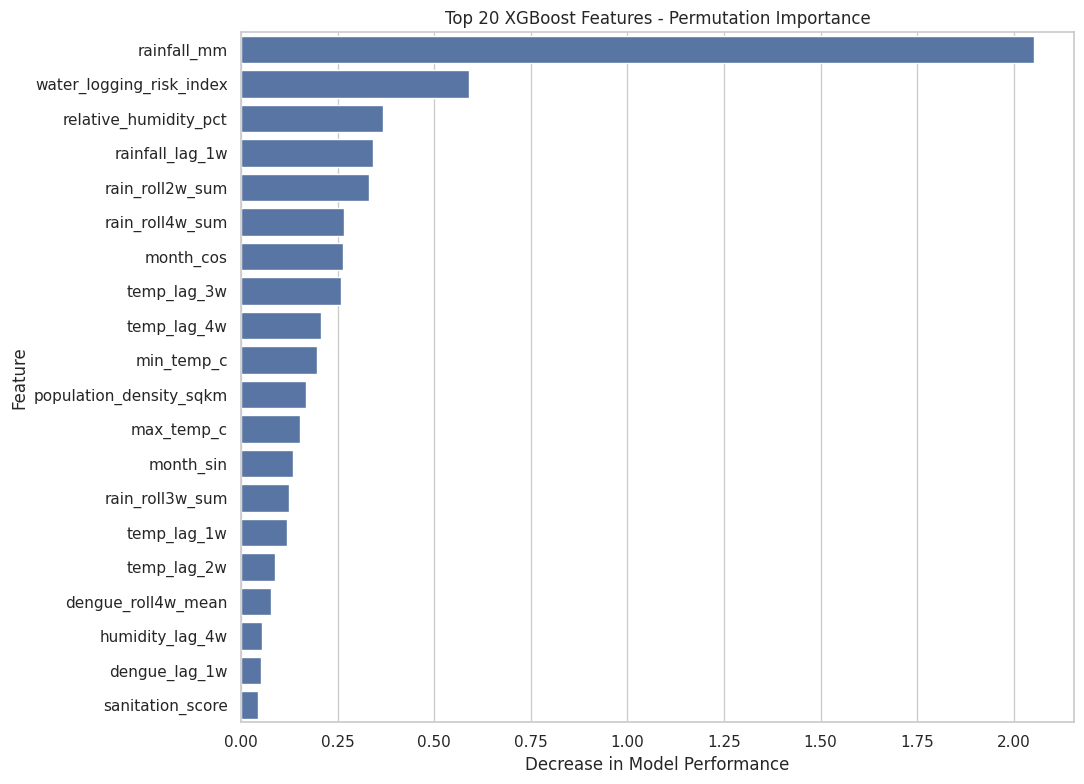

In [ ]:
plt.figure(figsize=(11, 8))

sns.barplot(
    data=importance_df.head(20),
    x='Importance',
    y='Feature'
)

plt.title('Top 20 XGBoost Features - Permutation Importance')
plt.xlabel('Decrease in Model Performance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.compose import TransformedTargetRegressor

In [ ]:
xgb_log_pipeline = TransformedTargetRegressor(
    regressor=Pipeline([
        ('preprocessor', preprocessor),
        ('model', XGBRegressor(
            n_estimators=500,
            learning_rate=0.03,
            max_depth=5,
            min_child_weight=3,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.1,
            reg_lambda=2,
            objective='reg:squarederror',
            eval_metric='rmse',
            random_state=42,
            n_jobs=-1
        ))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

In [ ]:
print("Training Log-Transformed XGBoost...")

xgb_log_pipeline.fit(
    X_train,
    y_train
)

print("Training completed!")

Training Log-Transformed XGBoost...
Training completed!


In [ ]:
log_predictions = xgb_log_pipeline.predict(X_val)

log_predictions = np.maximum(
    log_predictions,
    0
)

log_mae = mean_absolute_error(
    y_val,
    log_predictions
)

log_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        log_predictions
    )
)

log_r2 = r2_score(
    y_val,
    log_predictions
)

print("Log-Transformed XGBoost")
print("-" * 40)

print(f"MAE:  {log_mae:.4f}")
print(f"RMSE: {log_rmse:.4f}")
print(f"R2:   {log_r2:.4f}")

Log-Transformed XGBoost
----------------------------------------
MAE:  2.3411
RMSE: 4.9224
R2:   0.8652


In [ ]:
transformation_comparison = pd.DataFrame([
    {
        'Model': 'Original XGBoost',
        'MAE': xgb_mae,
        'RMSE': xgb_rmse,
        'R2': xgb_r2
    },
    {
        'Model': 'Log-Transformed XGBoost',
        'MAE': log_mae,
        'RMSE': log_rmse,
        'R2': log_r2
    }
])

transformation_comparison

,Model,MAE,RMSE,R2
0,Original XGBoost,2.137119,4.372975,0.893622
1,Log-Transformed XGBoost,2.341061,4.922361,0.865213


In [ ]:
log_evaluation = pd.DataFrame({
    'Actual': y_val.values,
    'Predicted': log_predictions
})

log_evaluation['Risk_Group'] = pd.cut(
    log_evaluation['Actual'],
    bins=[-0.001, 1, 13, 30, np.inf],
    labels=[
        'Zero–1 Cases',
        '2–13 Cases',
        '14–30 Cases',
        'Above 30 Cases'
    ]
)

log_risk_performance = log_evaluation.groupby(
    'Risk_Group',
    observed=False
).apply(
    lambda group: pd.Series({
        'Samples': len(group),
        'MAE': mean_absolute_error(
            group['Actual'],
            group['Predicted']
        ),
        'Mean Actual': group['Actual'].mean(),
        'Mean Predicted': group['Predicted'].mean()
    })
).reset_index()

log_risk_performance

,Risk_Group,Samples,MAE,Mean Actual,Mean Predicted
0,Zero–1 Cases,2627.0,0.325469,0.149220,0.338878
1,2–13 Cases,915.0,2.862524,4.544262,4.512969
2,14–30 Cases,460.0,5.490973,21.819565,18.345892
3,Above 30 Cases,378.0,11.253389,43.267196,32.575737


In [ ]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.base import clone
from xgboost import XGBRegressor

In [ ]:
train_sorted = train_df.sort_values(
    ['date', 'ward_id']
).reset_index(drop=True)

X_train_tune = train_sorted[feature_columns]
y_train_tune = train_sorted[target]

dates = train_sorted['date'].values

unique_dates = np.sort(
    train_sorted['date'].unique()
)

date_to_index = {
    date: idx
    for idx, date in enumerate(unique_dates)
}

date_indices = np.array([
    date_to_index[date]
    for date in dates
])

In [ ]:
tscv = TimeSeriesSplit(
    n_splits=4,
    gap=4
)

cv_splits = []

for train_idx, val_idx in tscv.split(unique_dates):

    train_dates = set(unique_dates[train_idx])
    val_dates = set(unique_dates[val_idx])

    fold_train_idx = np.where(
        np.isin(dates, list(train_dates))
    )[0]

    fold_val_idx = np.where(
        np.isin(dates, list(val_dates))
    )[0]

    cv_splits.append((
        fold_train_idx,
        fold_val_idx
    ))

print("Number of chronological folds:", len(cv_splits))

Number of chronological folds: 4


In [ ]:
param_grid = {
    'model__n_estimators': [300, 500, 700, 900],
    'model__max_depth': [3, 4, 5, 6],
    'model__learning_rate': [0.01, 0.02, 0.03, 0.05],
    'model__min_child_weight': [1, 3, 5, 7],
    'model__subsample': [0.7, 0.8, 0.9],
    'model__colsample_bytree': [0.7, 0.8, 0.9],
    'model__reg_alpha': [0, 0.1, 0.5, 1],
    'model__reg_lambda': [1, 2, 5, 10]
}

In [ ]:
tuning_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('model', XGBRegressor(
        objective='reg:squarederror',
        eval_metric='mae',
        random_state=42,
        n_jobs=1
    ))
])

In [ ]:
random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring='neg_mean_absolute_error',
    cv=cv_splits,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(
    X_train_tune,
    y_train_tune
)

print("Best CV MAE:", -random_search.best_score_)
print("\nBest parameters:")
print(random_search.best_params_)

Fitting 4 folds for each of 25 candidates, totalling 100 fits
Best CV MAE: 3.0661100130466865

Best parameters:
{'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__reg_alpha': 0.5, 'model__n_estimators': 700, 'model__min_child_weight': 1, 'model__max_depth': 6, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.7}


In [ ]:
tuned_xgb = random_search.best_estimator_

tuned_predictions = tuned_xgb.predict(X_val)

tuned_predictions = np.maximum(
    tuned_predictions,
    0
)

tuned_mae = mean_absolute_error(
    y_val,
    tuned_predictions
)

tuned_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        tuned_predictions
    )
)

tuned_r2 = r2_score(
    y_val,
    tuned_predictions
)

print("Tuned XGBoost")
print("-" * 35)

print(f"MAE:  {tuned_mae:.4f}")
print(f"RMSE: {tuned_rmse:.4f}")
print(f"R2:   {tuned_r2:.4f}")

Tuned XGBoost
-----------------------------------
MAE:  2.1827
RMSE: 4.5241
R2:   0.8861


In [ ]:
print("Current dengue cases included:",
      'dengue_cases' in feature_columns)

print("\nAvailable dengue-related features:")

print([
    col for col in feature_columns
    if 'dengue' in col.lower()
])

Current dengue cases included: False

Available dengue-related features:
['dengue_lag_1w', 'dengue_lag_2w', 'dengue_lag_3w', 'dengue_lag_4w', 'dengue_roll4w_mean']


In [ ]:
print("X_train columns:")
print(X_train.columns.tolist())

print("\nX_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nIndex alignment:", X_train.index.equals(y_train.index))

X_train columns:
['population_density_sqkm', 'water_logging_risk_index', 'sanitation_score', 'avg_temp_c', 'max_temp_c', 'min_temp_c', 'rainfall_mm', 'relative_humidity_pct', 'rainfall_lag_1w', 'rainfall_lag_2w', 'rainfall_lag_3w', 'rainfall_lag_4w', 'rain_roll2w_sum', 'rain_roll3w_sum', 'rain_roll4w_sum', 'temp_lag_1w', 'temp_lag_2w', 'temp_lag_3w', 'temp_lag_4w', 'humidity_lag_1w', 'humidity_lag_2w', 'humidity_lag_3w', 'humidity_lag_4w', 'dengue_lag_1w', 'dengue_lag_2w', 'dengue_lag_3w', 'dengue_lag_4w', 'dengue_roll4w_mean', 'month_sin', 'month_cos', 'city', 'ward_id']

X_train shape: (21360, 32)
y_train shape: (21360,)

Index alignment: True


In [ ]:
print("Original dataset columns:")
print(df.columns.tolist())

print("\nOriginal dataset shape:", df.shape)

Original dataset columns:
['date', 'city', 'ward_id', 'population_density_sqkm', 'water_logging_risk_index', 'sanitation_score', 'avg_temp_c', 'max_temp_c', 'min_temp_c', 'rainfall_mm', 'relative_humidity_pct', 'dengue_cases', 'month', 'week', 'rainfall_lag_1w', 'temp_lag_1w', 'humidity_lag_1w', 'rainfall_lag_2w', 'temp_lag_2w', 'humidity_lag_2w', 'rainfall_lag_3w', 'temp_lag_3w', 'humidity_lag_3w', 'rainfall_lag_4w', 'temp_lag_4w', 'humidity_lag_4w', 'rain_roll4w_sum', 'date_diff', 'year_month', 'rain_roll2w_sum', 'rain_roll3w_sum', 'month_sin', 'month_cos', 'future_dengue_cases_2_4w', 'dengue_lag_1w', 'dengue_lag_2w', 'dengue_lag_3w', 'dengue_lag_4w', 'dengue_roll4w_mean']

Original dataset shape: (31320, 39)


In [ ]:
print(
    df[
        [
            'ward_id',
            'date',
            'dengue_cases',
            'dengue_lag_1w',
            'dengue_lag_2w',
            'dengue_lag_3w',
            'dengue_lag_4w',
            'dengue_roll4w_mean'
        ]
    ].head(15)
)

        ward_id       date  dengue_cases  dengue_lag_1w  dengue_lag_2w  \
0   CCC_Ward_01 2016-01-04             0            NaN            NaN   
1   CCC_Ward_01 2016-01-11             0            0.0            NaN   
2   CCC_Ward_01 2016-01-18             0            0.0            0.0   
3   CCC_Ward_01 2016-01-25             0            0.0            0.0   
4   CCC_Ward_01 2016-02-01             0            0.0            0.0   
5   CCC_Ward_01 2016-02-08             0            0.0            0.0   
6   CCC_Ward_01 2016-02-15             0            0.0            0.0   
7   CCC_Ward_01 2016-02-22             0            0.0            0.0   
8   CCC_Ward_01 2016-02-29             0            0.0            0.0   
9   CCC_Ward_01 2016-03-07             0            0.0            0.0   
10  CCC_Ward_01 2016-03-14             0            0.0            0.0   
11  CCC_Ward_01 2016-03-21             0            0.0            0.0   
12  CCC_Ward_01 2016-03-28            

In [ ]:
df = df.sort_values(
    ['ward_id', 'date']
).copy()

df['check_lag_1w'] = (
    df.groupby('ward_id')['dengue_cases'].shift(1)
)

df['check_lag_2w'] = (
    df.groupby('ward_id')['dengue_cases'].shift(2)
)

df['check_lag_3w'] = (
    df.groupby('ward_id')['dengue_cases'].shift(3)
)

df['check_lag_4w'] = (
    df.groupby('ward_id')['dengue_cases'].shift(4)
)

print(
    df[
        [
            'ward_id',
            'date',
            'dengue_cases',
            'dengue_lag_1w',
            'check_lag_1w',
            'dengue_lag_2w',
            'check_lag_2w'
        ]
    ].head(15)
)

        ward_id       date  dengue_cases  dengue_lag_1w  check_lag_1w  \
0   CCC_Ward_01 2016-01-04             0            NaN           NaN   
1   CCC_Ward_01 2016-01-11             0            0.0           0.0   
2   CCC_Ward_01 2016-01-18             0            0.0           0.0   
3   CCC_Ward_01 2016-01-25             0            0.0           0.0   
4   CCC_Ward_01 2016-02-01             0            0.0           0.0   
5   CCC_Ward_01 2016-02-08             0            0.0           0.0   
6   CCC_Ward_01 2016-02-15             0            0.0           0.0   
7   CCC_Ward_01 2016-02-22             0            0.0           0.0   
8   CCC_Ward_01 2016-02-29             0            0.0           0.0   
9   CCC_Ward_01 2016-03-07             0            0.0           0.0   
10  CCC_Ward_01 2016-03-14             0            0.0           0.0   
11  CCC_Ward_01 2016-03-21             0            0.0           0.0   
12  CCC_Ward_01 2016-03-28             0           

In [ ]:
df['check_roll4w_mean'] = (
    df.groupby('ward_id')['dengue_cases']
    .transform(
        lambda x: x.shift(1).rolling(
            window=4,
            min_periods=4
        ).mean()
    )
)

comparison = df[
    [
        'dengue_roll4w_mean',
        'check_roll4w_mean'
    ]
]

print(comparison.head(15))

print(
    "\nRolling feature matches:",
    np.allclose(
        comparison['dengue_roll4w_mean'],
        comparison['check_roll4w_mean'],
        equal_nan=True
    )
)

    dengue_roll4w_mean  check_roll4w_mean
0                  NaN                NaN
1                  NaN                NaN
2                  NaN                NaN
3                  NaN                NaN
4                  0.0                0.0
5                  0.0                0.0
6                  0.0                0.0
7                  0.0                0.0
8                  0.0                0.0
9                  0.0                0.0
10                 0.0                0.0
11                 0.0                0.0
12                 0.0                0.0
13                 0.0                0.0
14                 0.0                0.0

Rolling feature matches: True


In [ ]:
# Add current dengue_cases as an additional feature
new_feature_columns = feature_columns + ['dengue_cases']

# Rebuild model dataset from original df
model_df_new = df[
    ['date'] + new_feature_columns + [target]
].copy()

# Handle missing and infinite values
model_df_new = model_df_new.replace([np.inf, -np.inf], np.nan)

model_df_new = model_df_new.dropna(
    subset=new_feature_columns + [target]
)

# Sort chronologically
model_df_new = model_df_new.sort_values('date').reset_index(drop=True)

print("New dataset shape:", model_df_new.shape)
print("Missing values:", model_df_new.isnull().sum().sum())

New dataset shape: (30840, 35)
Missing values: 0


In [ ]:
train_df_new = model_df_new[
    model_df_new['date'] <= train_cutoff
].copy()

val_df_new = model_df_new[
    (model_df_new['date'] > train_cutoff) &
    (model_df_new['date'] <= val_cutoff)
].copy()

# Separate features and target
X_train_new = train_df_new[new_feature_columns]
y_train_new = train_df_new[target]

X_val_new = val_df_new[new_feature_columns]
y_val_new = val_df_new[target]

print("Training:", X_train_new.shape)
print("Validation:", X_val_new.shape)

Training: (21600, 33)
Validation: (4620, 33)


In [ ]:
print("Current dengue cases statistics:")
print(X_train_new['dengue_cases'].describe())

print("\nFirst 10 values:")
print(X_train_new['dengue_cases'].head(10))

Current dengue cases statistics:
count    21600.000000
mean         2.705185
std          4.664773
min          0.000000
25%          0.000000
50%          0.000000
75%          4.000000
max         41.000000
Name: dengue_cases, dtype: float64

First 10 values:
0    0
1    0
2    0
3    0
4    0
5    0
6    0
7    0
8    0
9    0
Name: dengue_cases, dtype: int64


In [ ]:
new_numeric_features = numeric_features + ['dengue_cases']

preprocessor_new = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', new_numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [ ]:
xgb_new = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2,
    objective='reg:squarederror',
    eval_metric='rmse',
    random_state=42,
    n_jobs=-1
)

xgb_pipeline_new = Pipeline([
    ('preprocessor', preprocessor_new),
    ('model', xgb_new)
])

xgb_pipeline_new.fit(X_train_new, y_train_new)

y_pred_new = xgb_pipeline_new.predict(X_val_new)

print("MAE:", mean_absolute_error(y_val_new, y_pred_new))
print("RMSE:", np.sqrt(mean_squared_error(y_val_new, y_pred_new)))
print("R2:", r2_score(y_val_new, y_pred_new))

MAE: 2.1812176069237688
RMSE: 4.350614758404871
R2: 0.8896305488053684


In [ ]:
y_pred_original = xgb_pipeline.predict(X_val)
print("Original XGBoost:")
display(evaluate_by_risk_group(y_val, y_pred_original))

print("XGBoost with current dengue cases:")
display(evaluate_by_risk_group(y_val_new, y_pred_new))

Original XGBoost:


,Samples,MAE,Actual Mean,Predicted Mean
risk_group,,,,
0-1 cases,2627.0,0.418251,0.149220,0.442476
2-13 cases,915.0,2.788642,4.544262,4.979682
14-30 cases,460.0,4.639964,21.819565,21.163879
Above 30,378.0,9.475272,43.267196,34.902596


XGBoost with current dengue cases:


,Samples,MAE,Actual Mean,Predicted Mean
risk_group,,,,
0-1 cases,2653.0,0.440306,0.154542,0.469741
2-13 cases,1107.0,2.883149,4.794941,5.534290
14-30 cases,482.0,4.547971,21.562241,20.973801
Above 30,378.0,9.326259,43.267196,35.097733


In [ ]:
# Find common validation indexes
common_idx = X_val.index.intersection(X_val_new.index)

# Select identical validation samples
X_val_common = X_val.loc[common_idx]
X_val_new_common = X_val_new.loc[common_idx]

y_val_common = y_val.loc[common_idx]
y_val_new_common = y_val_new.loc[common_idx]

# Generate predictions on identical samples
pred_original_common = xgb_pipeline.predict(X_val_common)
pred_new_common = xgb_pipeline_new.predict(X_val_new_common)

# Compare overall metrics
comparison = pd.DataFrame({
    'Model': ['Original XGBoost', 'XGBoost + Current Cases'],
    'MAE': [
        mean_absolute_error(y_val_common, pred_original_common),
        mean_absolute_error(y_val_new_common, pred_new_common)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_val_common, pred_original_common)),
        np.sqrt(mean_squared_error(y_val_new_common, pred_new_common))
    ],
    'R2': [
        r2_score(y_val_common, pred_original_common),
        r2_score(y_val_new_common, pred_new_common)
    ]
})

display(comparison)

,Model,MAE,RMSE,R2
0,Original XGBoost,1.840013,3.703869,0.908406
1,XGBoost + Current Cases,1.923678,3.604223,0.891069


In [ ]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    xgb_pipeline_new,
    X_val_new_common,
    y_val_new_common,
    n_repeats=5,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X_val_new_common.columns,
    'Importance': perm_result.importances_mean
}).sort_values('Importance', ascending=False)

display(importance_df.head(15))

,Feature,Importance
6,rainfall_mm,2.594433
7,relative_humidity_pct,0.617161
1,water_logging_risk_index,0.505937
5,min_temp_c,0.341098
14,rain_roll4w_sum,0.276774
17,temp_lag_3w,0.266426
29,month_cos,0.245735
15,temp_lag_1w,0.172618
4,max_temp_c,0.156573
27,dengue_roll4w_mean,0.154608


In [ ]:
print("Target creation code or definition:")
print("future_dengue_cases_2_4w")

print("\nSample records:")
display(
    df[
        ['ward_id', 'date', 'dengue_cases',
         'future_dengue_cases_2_4w']
    ].head(15)
)

Target creation code or definition:
future_dengue_cases_2_4w

Sample records:


,ward_id,date,dengue_cases,future_dengue_cases_2_4w
0,CCC_Ward_01,2016-01-04,0,0.0
1,CCC_Ward_01,2016-01-11,0,0.0
2,CCC_Ward_01,2016-01-18,0,0.0
3,CCC_Ward_01,2016-01-25,0,0.0
4,CCC_Ward_01,2016-02-01,0,0.0
5,CCC_Ward_01,2016-02-08,0,0.0
6,CCC_Ward_01,2016-02-15,0,0.0
7,CCC_Ward_01,2016-02-22,0,0.0
8,CCC_Ward_01,2016-02-29,0,0.0
9,CCC_Ward_01,2016-03-07,0,0.0


In [ ]:
# Sort data by ward and date
df = df.sort_values(
    ['ward_id', 'date']
).reset_index(drop=True)

# Recalculate target: cases in weeks +2, +3 and +4
df['target_check'] = (
    df.groupby('ward_id')['dengue_cases'].shift(-2)
    + df.groupby('ward_id')['dengue_cases'].shift(-3)
    + df.groupby('ward_id')['dengue_cases'].shift(-4)
)

# Compare original and reconstructed targets
comparison = df[
    ['future_dengue_cases_2_4w', 'target_check']
].dropna()

print("Total comparable rows:", len(comparison))

print(
    "Targets match:",
    np.allclose(
        comparison['future_dengue_cases_2_4w'],
        comparison['target_check']
    )
)

print("\nSample comparison:")
display(comparison.head(20))

Total comparable rows: 31080
Targets match: True

Sample comparison:


,future_dengue_cases_2_4w,target_check
0,0.0,0.0
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,0.0,0.0
5,0.0,0.0
6,0.0,0.0
7,0.0,0.0
8,0.0,0.0
9,0.0,0.0


In [ ]:
# Inspect weather and dengue features
display(
    df[
        [
            'ward_id',
            'date',
            'rainfall_mm',
            'avg_temp_c',
            'relative_humidity_pct',
            'dengue_cases',
            'future_dengue_cases_2_4w'
        ]
    ].head(20)
)

,ward_id,date,rainfall_mm,avg_temp_c,relative_humidity_pct,dengue_cases,future_dengue_cases_2_4w
0,CCC_Ward_01,2016-01-04,0.00,18.32,59.24,0,0.0
1,CCC_Ward_01,2016-01-11,2.02,21.24,61.63,0,0.0
2,CCC_Ward_01,2016-01-18,0.00,20.94,60.50,0,0.0
3,CCC_Ward_01,2016-01-25,1.52,21.75,69.02,0,0.0
4,CCC_Ward_01,2016-02-01,0.94,22.39,60.50,0,0.0
5,CCC_Ward_01,2016-02-08,4.17,24.55,49.88,0,0.0
6,CCC_Ward_01,2016-02-15,8.19,23.56,52.70,0,0.0
7,CCC_Ward_01,2016-02-22,3.61,22.66,60.54,0,0.0
8,CCC_Ward_01,2016-02-29,5.89,25.22,55.06,0,0.0
9,CCC_Ward_01,2016-03-07,0.00,25.71,64.79,0,0.0


In [ ]:
# Check each dataset
for name, data in {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}.items():

    print(f"\n{name} dataset")
    print("Rows:", len(data))
    print("Start:", data['date'].min())
    print("End:", data['date'].max())
    print("Unique dates:", data['date'].nunique())


# Check chronological separation
print("\nDate gaps:")

print(
    "Train -> Validation:",
    val_df['date'].min() - train_df['date'].max()
)

print(
    "Validation -> Test:",
    test_df['date'].min() - val_df['date'].max()
)


Train dataset
Rows: 21360
Start: 2016-02-01 00:00:00
End: 2022-11-21 00:00:00
Unique dates: 356

Validation dataset
Rows: 4380
Start: 2022-12-26 00:00:00
End: 2024-05-13 00:00:00
Unique dates: 73

Test dataset
Rows: 4620
Start: 2024-06-17 00:00:00
End: 2025-12-01 00:00:00
Unique dates: 77

Date gaps:
Train -> Validation: 35 days 00:00:00
Validation -> Test: 35 days 00:00:00


In [ ]:
XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2,
    objective='reg:squarederror',
    eval_metric='rmse',
    random_state=42,
    n_jobs=-1
)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=3, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=-1, num_parallel_tree=None, ...)

In [ ]:
# Combine training and validation datasets
final_train_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

# Separate features and target
X_final_train = final_train_df[feature_columns]
y_final_train = final_train_df[target]

# Keep test data untouched
X_final_test = test_df[feature_columns]
y_final_test = test_df[target]

print("Final training shape:", X_final_train.shape)
print("Final test shape:", X_final_test.shape)

print("Training + validation rows:", len(final_train_df))

Final training shape: (25740, 32)
Final test shape: (4620, 32)
Training + validation rows: 25740


In [ ]:
# Final preprocessing
final_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ]
)

# Final XGBoost configuration
final_xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2,
    objective='reg:squarederror',
    eval_metric='rmse',
    random_state=42,
    n_jobs=-1
)

# Complete pipeline
final_model = Pipeline([
    ('preprocessor', final_preprocessor),
    ('model', final_xgb)
])

# Train
final_model.fit(X_final_train, y_final_train)

print("Final XGBoost model training completed!")

Final XGBoost model training completed!


In [ ]:
# Generate test predictions
y_test_pred = final_model.predict(X_final_test)

# Calculate metrics
test_mae = mean_absolute_error(y_final_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_final_test, y_test_pred))
test_r2 = r2_score(y_final_test, y_test_pred)

print("FINAL TEST PERFORMANCE")
print("----------------------")
print(f"MAE:  {test_mae:.4f}")
print(f"RMSE: {test_rmse:.4f}")
print(f"R2:   {test_r2:.4f}")

FINAL TEST PERFORMANCE
----------------------
MAE:  2.7861
RMSE: 4.9234
R2:   0.8132


In [ ]:
# Create test prediction dataframe
test_results = pd.DataFrame({
    'actual': np.array(y_final_test),
    'predicted': np.array(y_test_pred)
})

# Classify observations by actual dengue cases
test_results['risk_group'] = pd.cut(
    test_results['actual'],
    bins=[-1, 1, 13, 30, np.inf],
    labels=['0-1 cases', '2-13 cases', '14-30 cases', 'Above 30']
)

# Evaluate each group
risk_analysis = test_results.groupby(
    'risk_group',
    observed=False
).apply(
    lambda x: pd.Series({
        'Samples': len(x),
        'MAE': mean_absolute_error(
            x['actual'], x['predicted']
        ),
        'Actual Mean': x['actual'].mean(),
        'Predicted Mean': x['predicted'].mean()
    })
)

display(risk_analysis.round(3))

,Samples,MAE,Actual Mean,Predicted Mean
risk_group,,,,
0-1 cases,2324.0,0.394,0.129,0.395
2-13 cases,885.0,4.602,6.740,10.036
14-30 cases,1143.0,5.221,20.872,22.878
Above 30,268.0,7.144,36.657,33.333


In [ ]:
print("Negative predictions:", (y_test_pred < 0).sum())
print("Total predictions:", len(y_test_pred))
print("Minimum prediction:", y_test_pred.min())
print("Maximum prediction:", y_test_pred.max())

Negative predictions: 377
Total predictions: 4620
Minimum prediction: -1.8632996
Maximum prediction: 54.1296


In [ ]:
from sklearn.dummy import DummyRegressor

dummy_model = DummyRegressor(strategy='mean')
dummy_model.fit(X_final_train, y_final_train)

dummy_pred = dummy_model.predict(X_final_test)

print("Dummy MAE:",
      mean_absolute_error(y_final_test, dummy_pred))

print("XGBoost MAE:", test_mae)

Dummy MAE: 9.516688362142908
XGBoost MAE: 2.786087731397557


In [ ]:
y_test_pred_clipped = np.maximum(y_test_pred, 0)

print("Negative predictions after clipping:",
      (y_test_pred_clipped < 0).sum())

print("MAE before clipping:",
      mean_absolute_error(y_final_test, y_test_pred))

print("MAE after clipping:",
      mean_absolute_error(y_final_test, y_test_pred_clipped))

Negative predictions after clipping: 0
MAE before clipping: 2.786087731397557
MAE after clipping: 2.776195770472596


In [ ]:
test_results = pd.DataFrame({
    'actual': np.array(y_final_test),
    'predicted': np.array(y_test_pred_clipped)
})

test_results['risk_group'] = pd.cut(
    test_results['actual'],
    bins=[-1, 1, 13, 30, np.inf],
    labels=['0-1 cases', '2-13 cases', '14-30 cases', 'Above 30']
)

risk_analysis = test_results.groupby(
    'risk_group', observed=False
).apply(
    lambda x: pd.Series({
        'Samples': len(x),
        'MAE': mean_absolute_error(x['actual'], x['predicted']),
        'Actual Mean': x['actual'].mean(),
        'Predicted Mean': x['predicted'].mean()
    })
)

display(risk_analysis.round(3))

,Samples,MAE,Actual Mean,Predicted Mean
risk_group,,,,
0-1 cases,2324.0,0.376,0.129,0.414
2-13 cases,885.0,4.598,6.740,10.040
14-30 cases,1143.0,5.221,20.872,22.878
Above 30,268.0,7.144,36.657,33.333


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Actual and predicted outbreak labels
actual_outbreak = (y_final_test > 30).astype(int)
predicted_outbreak = (y_test_pred_clipped > 30).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(actual_outbreak, predicted_outbreak))

print("\nClassification Report:")
print(classification_report(
    actual_outbreak,
    predicted_outbreak,
    target_names=["Not High-Risk", "High-Risk"]
))

print("High-Risk Recall:",
      recall_score(actual_outbreak, predicted_outbreak))

Confusion Matrix:
[[4161  191]
 [ 103  165]]

Classification Report:
               precision    recall  f1-score   support

Not High-Risk       0.98      0.96      0.97      4352
    High-Risk       0.46      0.62      0.53       268

     accuracy                           0.94      4620
    macro avg       0.72      0.79      0.75      4620
 weighted avg       0.95      0.94      0.94      4620

High-Risk Recall: 0.6156716417910447


In [ ]:
# Create a detailed test result dataframe
test_results = pd.DataFrame({
    'actual': np.array(y_final_test),
    'predicted': np.array(y_test_pred_clipped)
})

# Calculate absolute error
test_results['error'] = (
    test_results['actual'] - test_results['predicted']
)

# Identify missed high-risk observations
missed_outbreaks = test_results[
    (test_results['actual'] > 30) &
    (test_results['predicted'] <= 30)
].sort_values('actual', ascending=False)

print("Missed high-risk observations:",
      len(missed_outbreaks))

display(missed_outbreaks.head(20))

Missed high-risk observations: 103


,actual,predicted,error
160,50.0,29.593967,20.406033
1445,47.0,27.886776,19.113224
237,46.0,22.412556,23.587444
512,43.0,28.693647,14.306353
6,43.0,29.935347,13.064653
4010,43.0,28.716196,14.283804
239,42.0,28.552883,13.447117
3856,42.0,22.646317,19.353683
1623,42.0,29.526262,12.473738
1138,41.0,26.212229,14.787771


In [ ]:
import pandas as pd
import numpy as np

def target_summary(name, data):
    y = data[target]

    return {
        'Dataset': name,
        'Samples': len(y),
        'Mean': y.mean(),
        'Median': y.median(),
        'Std': y.std(),
        'Maximum': y.max(),
        'Above 30': (y > 30).sum(),
        'Above 30 (%)': (y > 30).mean() * 100
    }

distribution = pd.DataFrame([
    target_summary('Train', train_df),
    target_summary('Validation', val_df),
    target_summary('Test', test_df)
])

display(distribution.round(3))

,Dataset,Samples,Mean,Median,Std,Maximum,Above 30,Above 30 (%)
0,Train,21360,8.206,1.0,12.667,92.0,1644,7.697
1,Validation,4380,7.064,0.0,13.409,90.0,378,8.630
2,Test,4620,8.646,1.0,11.392,57.0,268,5.801


In [ ]:
for name, data in [
    ('Train', train_df),
    ('Validation', val_df),
    ('Test', test_df)
]:
    print(f"\n{name}")
    print(data[target].describe(percentiles=[
        0.50, 0.75, 0.90, 0.95, 0.99
    ]))


Train
count    21360.000000
mean         8.205899
std         12.667424
min          0.000000
50%          1.000000
75%         14.000000
90%         27.000000
95%         36.000000
99%         51.000000
max         92.000000
Name: future_dengue_cases_2_4w, dtype: float64

Validation
count    4380.000000
mean        7.064384
std        13.409102
min         0.000000
50%         0.000000
75%         5.000000
90%        28.000000
95%        38.050000
99%        56.000000
max        90.000000
Name: future_dengue_cases_2_4w, dtype: float64

Test
count    4620.000000
mean        8.646320
std        11.391573
min         0.000000
50%         1.000000
75%        17.000000
90%        26.000000
95%        32.000000
99%        41.000000
max        57.000000
Name: future_dengue_cases_2_4w, dtype: float64


In [ ]:
# Create sample weights based on target values
y_train = y_train.reset_index(drop=True)

sample_weights = np.ones(len(y_train))

sample_weights[y_train > 13] = 1.5
sample_weights[y_train > 30] = 2.0

print("Weight distribution:")
print(pd.Series(sample_weights).value_counts().sort_index())

Weight distribution:
1.0    15998
1.5     3718
2.0     1644
Name: count, dtype: int64


In [ ]:
weighted_model = Pipeline([
    ('preprocessor', final_preprocessor),
    ('model', XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=5,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=2,
        objective='reg:squarederror',
        eval_metric='rmse',
        random_state=42,
        n_jobs=-1
    ))
])

weighted_model.fit(
    X_train,
    y_train,
    model__sample_weight=sample_weights
)

print("Weighted XGBoost training completed.")

Weighted XGBoost training completed.


In [ ]:
y_val_pred_weighted = weighted_model.predict(X_val)

print("WEIGHTED XGBOOST - VALIDATION")
print("-----------------------------")
print("MAE:", mean_absolute_error(y_val, y_val_pred_weighted))
print("RMSE:", np.sqrt(mean_squared_error(y_val, y_val_pred_weighted)))
print("R2:", r2_score(y_val, y_val_pred_weighted))

WEIGHTED XGBOOST - VALIDATION
-----------------------------
MAE: 2.218376292998623
RMSE: 4.539407245421573
R2: 0.8853700669407782


In [ ]:
# Original model predictions on validation
y_val_pred_original = best_model.predict(X_val)

# Apply non-negative constraint
original_pred = np.maximum(y_val_pred_original, 0)
weighted_pred = np.maximum(y_val_pred_weighted, 0)

# Actual high-risk labels
actual_high_risk = (np.array(y_val) > 30).astype(int)

# Predicted high-risk labels
original_high_risk = (original_pred > 30).astype(int)
weighted_high_risk = (weighted_pred > 30).astype(int)

from sklearn.metrics import recall_score, precision_score, f1_score

comparison = pd.DataFrame({
    'Model': ['Original XGBoost', 'Weighted XGBoost'],
    'MAE': [
        mean_absolute_error(y_val, original_pred),
        mean_absolute_error(y_val, weighted_pred)
    ],
    'High-Risk Recall': [
        recall_score(actual_high_risk, original_high_risk),
        recall_score(actual_high_risk, weighted_high_risk)
    ],
    'High-Risk Precision': [
        precision_score(actual_high_risk, original_high_risk, zero_division=0),
        precision_score(actual_high_risk, weighted_high_risk, zero_division=0)
    ],
    'High-Risk F1': [
        f1_score(actual_high_risk, original_high_risk, zero_division=0),
        f1_score(actual_high_risk, weighted_high_risk, zero_division=0)
    ]
})

display(comparison.round(4))

,Model,MAE,High-Risk Recall,High-Risk Precision,High-Risk F1
0,Original XGBoost,2.2197,0.6561,0.8522,0.7414
1,Weighted XGBoost,2.2168,0.6693,0.8433,0.7463


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [15, 20, 25, 30, 35, 40]

actual_high_risk = (np.array(y_val) > 30).astype(int)

results = []

for model_name, predictions in [
    ('Original XGBoost', original_pred),
    ('Weighted XGBoost', weighted_pred)
]:
    for threshold in thresholds:

        predicted_high_risk = (
            predictions > threshold
        ).astype(int)

        results.append({
            'Model': model_name,
            'Threshold': threshold,
            'Precision': precision_score(
                actual_high_risk,
                predicted_high_risk,
                zero_division=0
            ),
            'Recall': recall_score(
                actual_high_risk,
                predicted_high_risk,
                zero_division=0
            ),
            'F1': f1_score(
                actual_high_risk,
                predicted_high_risk,
                zero_division=0
            )
        })

threshold_results = pd.DataFrame(results)

display(
    threshold_results.round(4)
)

,Model,Threshold,Precision,Recall,F1
0,Original XGBoost,15,0.4415,0.9974,0.6120
1,Original XGBoost,20,0.5825,0.9709,0.7282
2,Original XGBoost,25,0.7541,0.8439,0.7965
3,Original XGBoost,30,0.8522,0.6561,0.7414
4,Original XGBoost,35,0.9206,0.4603,0.6138
5,Original XGBoost,40,0.9720,0.2751,0.4289
6,Weighted XGBoost,15,0.4380,1.0000,0.6092
7,Weighted XGBoost,20,0.5436,0.9735,0.6976
8,Weighted XGBoost,25,0.7121,0.8704,0.7833
9,Weighted XGBoost,30,0.8433,0.6693,0.7463


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

actual_high_risk = (np.array(y_val) > 30).astype(int)

predicted_high_risk_25 = (
    original_pred > 25
).astype(int)

print("Confusion Matrix - Original XGBoost (Threshold 25)")
print(confusion_matrix(
    actual_high_risk,
    predicted_high_risk_25
))

print("\nClassification Report:")
print(classification_report(
    actual_high_risk,
    predicted_high_risk_25,
    target_names=["Not High-Risk", "High-Risk"]
))

Confusion Matrix - Original XGBoost (Threshold 25)
[[3898  104]
 [  59  319]]

Classification Report:
               precision    recall  f1-score   support

Not High-Risk       0.99      0.97      0.98      4002
    High-Risk       0.75      0.84      0.80       378

     accuracy                           0.96      4380
    macro avg       0.87      0.91      0.89      4380
 weighted avg       0.97      0.96      0.96      4380



In [ ]:
print("Original model MAE:",
      mean_absolute_error(y_val, original_pred))

print("Original model RMSE:",
      np.sqrt(mean_squared_error(y_val, original_pred)))

print("Original model R2:",
      r2_score(y_val, original_pred))

print("Validation rows:", len(y_val))
print("Prediction rows:", len(original_pred))

Original model MAE: 2.219652940079614
Original model RMSE: 4.563971924095676
Original model R2: 0.8841260867476366
Validation rows: 4380
Prediction rows: 4380


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Apply the non-negative prediction constraint
final_test_predictions = np.maximum(y_test_pred, 0)

# Actual high-risk observations
actual_test_risk = (
    np.array(y_final_test) > 30
).astype(int)

# Predicted high-risk observations
predicted_test_risk = (
    final_test_predictions > 25
).astype(int)

print("FINAL TEST - OUTBREAK DETECTION")
print("--------------------------------")

print("\nConfusion Matrix:")
print(confusion_matrix(
    actual_test_risk,
    predicted_test_risk
))

print("\nClassification Report:")
print(classification_report(
    actual_test_risk,
    predicted_test_risk,
    target_names=["Not High-Risk", "High-Risk"]
))

print("High-Risk Precision:",
      precision_score(actual_test_risk, predicted_test_risk))

print("High-Risk Recall:",
      recall_score(actual_test_risk, predicted_test_risk))

print("High-Risk F1:",
      f1_score(actual_test_risk, predicted_test_risk))

FINAL TEST - OUTBREAK DETECTION
--------------------------------

Confusion Matrix:
[[3935  417]
 [  36  232]]

Classification Report:
               precision    recall  f1-score   support

Not High-Risk       0.99      0.90      0.95      4352
    High-Risk       0.36      0.87      0.51       268

     accuracy                           0.90      4620
    macro avg       0.67      0.88      0.73      4620
 weighted avg       0.95      0.90      0.92      4620

High-Risk Precision: 0.3574730354391371
High-Risk Recall: 0.8656716417910447
High-Risk F1: 0.5059978189749182


In [ ]:
import joblib
import os

# Create deployment directory
os.makedirs("dengue_model", exist_ok=True)

# Save complete trained pipeline
joblib.dump(
    final_model,
    "dengue_model/dengue_xgboost_model.joblib"
)

print("Model saved successfully!")
print("File size:",
      round(os.path.getsize(
          "dengue_model/dengue_xgboost_model.joblib"
      ) / 1024, 2), "KB")


Model saved successfully!
File size: 1296.32 KB


In [ ]:
model_config = {
    "model_name": "Dengue Forecasting XGBoost",
    "target": "future_dengue_cases_2_4w",
    "target_definition": "Cumulative dengue cases in weeks +2, +3 and +4",
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "feature_columns": feature_columns,
    "alert_threshold": 25,
    "actual_high_risk_threshold": 30,
    "prediction_constraint": "Non-negative; clip predictions below zero to zero",
    "model_type": "XGBRegressor",
    "random_state": 42
}

joblib.dump(
    model_config,
    "dengue_model/model_config.joblib"
)

print("Model configuration saved!")

Model configuration saved!


In [ ]:
print(os.listdir("dengue_model"))

['model_config.joblib', 'dengue_xgboost_model.joblib']


In [ ]:
def predict_dengue(input_data, model=final_model):

    # Convert input into DataFrame
    input_df = pd.DataFrame([input_data])

    # Ensure correct feature order
    input_df = input_df[feature_columns]

    # Generate prediction
    prediction = model.predict(input_df)[0]

    # Dengue cases cannot be negative
    prediction = max(0, prediction)

    # Determine alert level
    if prediction > 25:
        alert = "High Risk"
    else:
        alert = "Below Alert Threshold"

    return {
        "predicted_cases": round(float(prediction), 2),
        "alert": alert
    }

In [ ]:
sample_input = X_final_test.iloc[0].to_dict()

result = predict_dengue(sample_input)

print(result)

{'predicted_cases': 15.88, 'alert': 'Below Alert Threshold'}


In [ ]:
%%writefile dengue_model/predict.py

import joblib
import pandas as pd
import os

# Get the directory containing this Python file
BASE_DIR = os.path.dirname(os.path.abspath(__file__))

# Load model and configuration
model = joblib.load(
    os.path.join(BASE_DIR, "dengue_xgboost_model.joblib")
)

config = joblib.load(
    os.path.join(BASE_DIR, "model_config.joblib")
)

def predict_dengue(input_data):

    input_df = pd.DataFrame([input_data])

    required_features = config["feature_columns"]

    missing_features = [
        col for col in required_features
        if col not in input_df.columns
    ]

    if missing_features:
        raise ValueError(f"Missing features: {missing_features}")

    input_df = input_df[required_features]

    prediction = float(model.predict(input_df)[0])
    prediction = max(0.0, prediction)

    alert = (
        "High Risk"
        if prediction > config["alert_threshold"]
        else "Below Alert Threshold"
    )

    return {
        "predicted_cases": round(prediction, 2),
        "alert": alert
    }

Overwriting dengue_model/predict.py


In [ ]:
import sys
import importlib

sys.path.insert(0, "dengue_model")

import predict
importlib.reload(predict)

result = predict.predict_dengue(sample_input)

print(result)

{'predicted_cases': 15.88, 'alert': 'Below Alert Threshold'}


In [ ]:
%%writefile dengue_model/model_report.md

# Dengue Forecasting Model Report

## 1. Project Overview

This project forecasts dengue cases at the ward level in Chattogram, Bangladesh.

The model predicts the cumulative dengue cases expected in:
- Two weeks ahead
- Three weeks ahead
- Four weeks ahead

Target definition:

future_dengue_cases_2_4w = cases in week +2 + cases in week +3 + cases in week +4

## 2. Dataset

- Data frequency: Weekly
- Geographic level: Ward
- Historical period: 2016–2025
- Original dataset shape: 31,320 rows and 39 columns
- Final training features: 32

Features include:
- Weather measurements
- Historical weather lags
- Rolling rainfall statistics
- Historical dengue case lags
- Ward and city identifiers
- Seasonal features

## 3. Data Splitting

Chronological splitting was used to respect the time-series nature of the data.

| Dataset | Rows |
|---|---:|
| Training | 21,360 |
| Validation | 4,380 |
| Testing | 4,620 |

A four-week purge gap was applied between the splits to reduce target-horizon overlap.

The final model was trained using 25,740 training and validation observations.

## 4. Model

Algorithm: XGBoost Regressor

Hyperparameters:

- n_estimators: 500
- learning_rate: 0.03
- max_depth: 5
- min_child_weight: 3
- subsample: 0.8
- colsample_bytree: 0.8
- reg_alpha: 0.1
- reg_lambda: 2
- random_state: 42

Preprocessing:
- Numerical features: passthrough
- Categorical features: OneHotEncoder
- Unknown categories: ignored

The saved pipeline includes preprocessing and the trained model.

## 5. Final Test Performance

Evaluated on the untouched chronological test split:

| Metric | Result |
|---|---:|
| MAE | 2.7861 |
| RMSE | 4.9234 |
| R² | 0.8132 |

Dummy baseline MAE: 9.5167

The XGBoost model achieved approximately 70.7% lower MAE than the dummy baseline.

These regression metrics were calculated on the raw model predictions, before clipping negative predictions to zero.

## 6. Experimental Alert System

The selected prediction alert threshold is 25 cases.

- Predicted value > 25: High Risk
- Predicted value <= 25: Below Alert Threshold

The threshold was selected using validation data.

For evaluation, actual high risk was defined as more than 30 future cases.

Validation results at the selected alert threshold:
- Precision: 0.7541
- Recall: 0.8439
- F1-score: 0.7965

Test results at the same threshold:
- Precision: 0.3575
- Recall: 0.8657
- F1-score: 0.5060

The test results show that the alert system catches many high-risk observations but also generates substantial false alarms.

This threshold is experimental, not an officially approved public-health threshold.

## 7. Prediction Constraints

Dengue case counts cannot be negative.

Therefore, negative model predictions are clipped to zero before being returned by the prediction function.

## 8. Important Deployment Assumptions

- Input features must represent the relevant ward and current observation week.
- Current-week weather observations must be available before forecasting.
- Lag and rolling features must be calculated correctly from historical data.
- Categorical values such as city and ward identifiers must match the expected input format.
- All required model features must be supplied to the prediction function.

## 9. Limitations

- Model performance may vary across future time periods and wards.
- The test alert precision is substantially lower than validation precision.
- False alerts may occur.
- This is an experimental forecasting prototype, not a clinically or operationally validated public-health decision system.
- Predictions should be reviewed by relevant public-health professionals before being used for real-world decisions.

## 10. Project Files

- dengue_xgboost_model.joblib: Trained preprocessing and model pipeline.
- model_config.joblib: Model configuration and feature definitions.
- predict.py: Prediction function for backend integration.
- model_report.md: Model documentation and evaluation report.

Writing dengue_model/model_report.md


In [ ]:
import os

print(os.listdir("dengue_model"))

['model_config.joblib', 'dengue_xgboost_model.joblib', 'predict.py', 'model_report.md', '__pycache__']


In [ ]:
import shutil
import os

shutil.make_archive(
    "dengue_model_package",
    "zip",
    root_dir=".",
    base_dir="dengue_model"
)

print("ZIP package created successfully!")
print(os.path.getsize("dengue_model_package.zip"), "bytes")


ZIP package created successfully!
359084 bytes


In [ ]:
from google.colab import files

files.download("dengue_model_package.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>